# 🚀 Transformer e Large Language Models — Versione Annotata per Lezione

Questa è una versione commentata di `05_Transformer_e_LLM.ipynb`, pensata per essere presentata in aula.

Il codice è funzionalmente identico all'originale (stessa logica, stessi calcoli, stesso output atteso),
ma è stato **riscritto con molti più commenti inline**, e ogni blocco di codice è preceduto da una
spiegazione che segue sempre lo stesso schema fisso:

- **🔗 Legame col blocco precedente** — cosa riprende (o esplicitamente NON riprende) dal blocco prima;
- **🔍 Cosa viene fatto realmente** — cosa viene davvero eseguito dal computer (vs. cosa è solo teoria/disegno/simulazione);
- **🎯 Obiettivo** — perché questo blocco esiste, cosa vuole insegnare.

(Le uniche righe di codice disattivate rispetto all'originale sono i comandi `!pip install`, commentati per
evitare reinstallazioni accidentali durante una lezione dal vivo.)

## 🗺️ Roadmap della lezione

| # | Blocco | Cosa vedremo |
|---|--------|---------------|
| 1 | Setup | Import delle librerie |
| 2 | RNN vs Transformer | Perché è nato il Transformer (solo teoria) |
| 3 | Self-Attention | La formula `softmax(QKᵗ/√d_k)V`, implementata a mano |
| 4 | Multi-Head Attention | Più "teste" di attenzione in parallelo |
| 5 | Transformer completo (Keras) | Un intero stack encoder, **non addestrato** |
| 6 | LLM vero: GPT-2 | Un modello decoder, **pre-addestrato**, che genera testo davvero |
| 7 | Applicazioni pratiche | Attenzione: qui **non si usa nessun modello**, è tutto simulato |
| 8 | Riepilogo | Confronto finale e domande per la discussione |

## ❓ La domanda guida di questa lezione

> **Il modello costruito in questo notebook è "solo encoder"?**

Teniamo questa domanda in mente. La risposta non è banale, perché il notebook contiene **due architetture
diverse e indipendenti**: una costruita a mano (che è un encoder) e una scaricata già pronta (che è un decoder).
Arriveremo alla risposta completa passo dopo passo, e la riassumeremo alla fine.

## 🔧 Blocco 1 — Setup

**🔗 Legame col blocco precedente:** nessuno — è il primo blocco. Prepara gli strumenti che useremo in
**tutti** i blocchi successivi.

**🔍 Cosa viene fatto realmente:** vengono importate le librerie (`numpy`/`pandas`/`matplotlib`/`seaborn` per
calcolo e grafici — usate ovunque; `tensorflow`/`keras` — usate SOLO nel Blocco 5; `transformers`/`torch` —
usate SOLO nel Blocco 6) e vengono fissati i seed random (`tf.random.set_seed(42)`, `np.random.seed(42)`,
`random.seed(42)`, `set_seed(42)`) così che le parti random del notebook (Blocco 4, e in parte il Blocco 6)
diano risultati riproducibili tra un'esecuzione e l'altra. Le righe `!pip install` sono commentate: le
librerie sono già installate nel virtual environment.

**🎯 Obiettivo:** rendere disponibili, in un colpo solo, tutte le librerie usate più avanti, così da poter
concentrarsi sui concetti nei blocchi successivi senza dover più parlare di import.

In [1]:
# ============================================================
# BLOCCO 1 — SETUP
# ============================================================
# Le righe di !pip install sono disattivate (commentate): il notebook
# stesso dichiara che le librerie sono già installate nel virtual
# environment tramite requirements.txt. Le lascio visibili solo come
# documentazione di COSA serve, non le eseguo per non reinstallare
# tutto ad ogni lezione dal vivo.
# !pip install transformers torch torchvision torchaudio
# !pip install tensorflow keras numpy matplotlib seaborn pandas plotly
# !pip install scikit-learn nltk wordcloud datasets
# !pip install accelerate sentencepiece

# ------------------------------------------------------------
# Libreria numeriche e di visualizzazione, usate ovunque nel notebook
# ------------------------------------------------------------
import numpy as np                       # calcolo su matrici/vettori: Blocchi 3, 4, 5 e i grafici finti del Blocco 6
import pandas as pd                       # tabelle (DataFrame): usato per mostrare la matrice di attention come tabella (Blocco 3) e nel riepilogo finale (Blocco 8)
import matplotlib.pyplot as plt           # tutti i grafici "fatti a mano" (Blocchi 2, 3, 4, 5, 6, 8)
import seaborn as sns                     # heatmap delle attention weights (Blocchi 3, 4) + palette colori
from collections import Counter, defaultdict   # importati per uso generico, non centrali in questo notebook
import re                                 # espressioni regolari, importate ma non usate in modo determinante qui
import random                             # random "puro" di Python, usato per il seed di riproducibilità
import math                               # funzioni matematiche di base (non strettamente necessarie: numpy le sostituisce quasi ovunque)
import warnings
warnings.filterwarnings('ignore')          # silenzia warning "cosmetici" delle librerie, per non sporcare l'output a lezione

# ------------------------------------------------------------
# TensorFlow/Keras — SERVIRANNO SOLO NEL BLOCCO 5
# ------------------------------------------------------------
# Qui vengono importati i "mattoncini" per costruire un modello neurale
# vero e allenabile (layers.Dense, layers.MultiHeadAttention, ecc.),
# che useremo per lo stack encoder del Blocco 5. Nei Blocchi 3-4 NON
# li useremo: lì lavoriamo solo con numpy puro.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers

# ------------------------------------------------------------
# Hugging Face Transformers — SERVIRANNO SOLO NEL BLOCCO 6
# ------------------------------------------------------------
# Queste classi NON sono scritte da noi: arrivano già pronte dalla
# libreria "transformers". GPT2LMHeadModel/GPT2Tokenizer sono il
# modello vero e pre-addestrato che useremo per generare testo davvero.
from transformers import (
    AutoTokenizer, AutoModel, AutoModelForCausalLM,
    GPT2LMHeadModel, GPT2Tokenizer,
    pipeline, set_seed
)

# ------------------------------------------------------------
# PyTorch — SERVIRA' SOLO NEL BLOCCO 6
# ------------------------------------------------------------
# GPT-2 (nella versione Hugging Face che useremo) è implementato in
# PyTorch, non in TensorFlow: per questo importiamo anche torch, anche
# se il Blocco 5 useremo invece TensorFlow/Keras. I due mondi convivono
# nel notebook ma non si mescolano mai in una singola cella.
import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# Plotly — importato ma di fatto NON utilizzato nel resto del notebook
# ------------------------------------------------------------
# Tutti i grafici che vedremo (Blocchi 2, 3, 4, 5, 6, 8) sono fatti con
# matplotlib/seaborn, non con plotly. Questo import è quindi superfluo
# per come è scritto il notebook: lo segnalo perché è un dettaglio utile
# da notare quando si legge codice non proprio (capita spesso di trovare
# import "morti").
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# ------------------------------------------------------------
# Configurazione e SEED per la riproducibilità
# ------------------------------------------------------------
# Fissare i semi random è importante perché più avanti useremo numeri
# casuali in punti "critici": i pesi random della Multi-Head Attention
# scritta a mano (Blocco 4) e il campionamento (sampling) nella
# generazione di testo con GPT-2 (Blocco 6). Con lo stesso seed,
# rieseguendo il notebook da capo si ottengono gli stessi risultati.
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
tf.random.set_seed(42)     # riproducibilità per i pesi random di TensorFlow/Keras (Blocco 5)
np.random.seed(42)         # riproducibilità per numpy (Blocchi 3, 4, e i grafici finti del Blocco 6)
random.seed(42)            # riproducibilità per il modulo random di Python
set_seed(42)               # riproducibilità per Hugging Face/PyTorch (Blocco 6: sampling di GPT-2)

# Nessun modello viene creato in questa cella: è solo import + configurazione.
print("✅ Setup completato! Pronti per esplorare i Transformer.")
print(f"🔧 TensorFlow version: {tf.__version__}")
print(f"🔧 PyTorch version: {torch.__version__}")


✅ Setup completato! Pronti per esplorare i Transformer.
🔧 TensorFlow version: 2.21.0
🔧 PyTorch version: 2.14.0+cpu


## 🌟 Blocco 2 — Perché è nato il Transformer (solo teoria)

**🔗 Legame col blocco precedente:** usa solo gli import fatti nel Blocco 1 (in particolare `matplotlib` per
il disegno finale). Non costruisce ancora nessuna classe né nessun modello.

**🔍 Cosa viene fatto realmente:** viene stampata una timeline storica, un elenco di problemi delle RNN
(elaborazione sequenziale, vanishing gradient, difficoltà con dipendenze a lungo raggio) e delle soluzioni
introdotte dal Transformer (elaborazione parallela, self-attention). Vengono poi disegnati due schemi con
`matplotlib`: a sinistra una catena RNN (`h1→h2→h3→h4→h5`), a destra un insieme di token tutti collegati tra
loro. **Il disegno di destra è solo concettuale**: quelle linee verdi rappresentano l'IDEA di self-attention,
non pesi di attenzione realmente calcolati — quei numeri veri arriveranno solo nel Blocco 3.

**🎯 Obiettivo:** costruire il "perché" prima del "come": motivare, con argomenti teorici, la necessità di
un'architettura alternativa alla RNN, prima di iniziare a scriverne il codice.

🌟 LA RIVOLUZIONE DEI TRANSFORMER

📅 TIMELINE STORICA:
   2017: 'Attention Is All You Need' - Nascita dei Transformer
   2018: BERT - Bidirectional Encoder Representations
   2019: GPT-2 - Generative Pre-trained Transformer
   2020: GPT-3 - 175B parametri, breakthrough
   2022: ChatGPT - AI conversazionale mainstream
   2023: GPT-4 - Multimodale, reasoning avanzato
   2024+: Era dei LLM specializzati e multimodali

❌ PROBLEMI DELLE RNN:
   🐌 Elaborazione sequenziale (non parallelizzabile)
   💭 Memoria limitata per sequenze lunghe
   📉 Vanishing gradient problem
   ⏱️ Addestramento lento
   🔄 Difficoltà con dipendenze a lungo raggio

✅ SOLUZIONI DEI TRANSFORMER:
   ⚡ Elaborazione parallela di tutta la sequenza
   🎯 Self-attention per catturare dipendenze globali
   📈 Scalabilità a sequenze molto lunghe
   🚀 Addestramento efficiente su GPU/TPU
   🔗 Connessioni dirette tra qualsiasi posizione


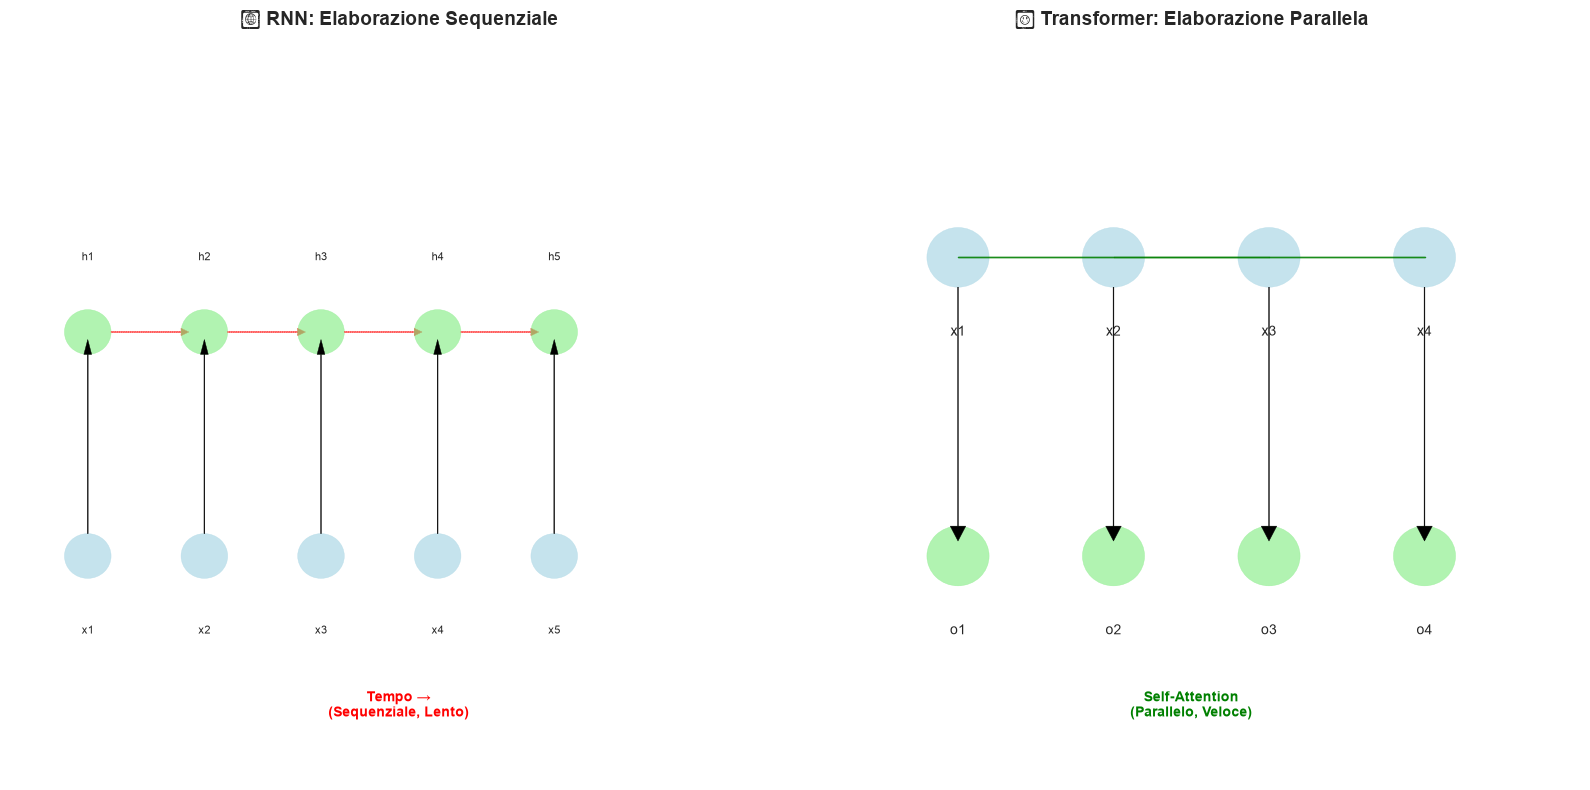


🎯 PRINCIPI CHIAVE DEI TRANSFORMER:
   🔍 Self-Attention: ogni token 'guarda' tutti gli altri
   📍 Positional Encoding: mantiene informazione di posizione
   🔄 Multi-Head Attention: attention parallele specializzate
   🏗️ Encoder-Decoder: architettura modulare
   📚 Pre-training + Fine-tuning: transfer learning

💫 IMPATTO DEI TRANSFORMER:
   🌐 Traduzione automatica di qualità umana
   💬 Chatbot conversazionali avanzati
   📝 Generazione di testo creativo
   🔍 Comprensione del linguaggio naturale
   🎨 AI multimodale (testo + immagini)
   🧠 Reasoning e problem solving

🔮 FUTURO:
   • Modelli sempre più grandi e capaci
   • Specializzazione per domini specifici
   • Integrazione multimodale avanzata
   • Efficienza e sostenibilità
   • AGI (Artificial General Intelligence)?


In [8]:
# ============================================================
# BLOCCO 2 — LA RIVOLUZIONE DEI TRANSFORMER (SOLO TEORIA)
# ============================================================
# NESSUN modello viene creato in questa cella. L'obiettivo è
# puramente concettuale: capire IL PERCHE' prima di scrivere codice
# che implementa qualcosa. Tre domande a cui rispondiamo:
#   1) perché le RNN hanno dei limiti?
#   2) quale idea introduce il Transformer?
#   3) quali sono i principi fondamentali della nuova architettura?
# ============================================================

print("🌟 LA RIVOLUZIONE DEI TRANSFORMER\n")


# ============================================================
# TIMELINE STORICA
# ============================================================
# Lista di tuple (anno, evento): un modo semplice per tenere insieme
# due informazioni collegate senza dover creare una classe.
# ============================================================

print("📅 TIMELINE STORICA:")

timeline = [
    ("2017", "'Attention Is All You Need' - Nascita dei Transformer"),
    ("2018", "BERT - Bidirectional Encoder Representations"),
    ("2019", "GPT-2 - Generative Pre-trained Transformer"),
    ("2020", "GPT-3 - 175B parametri, breakthrough"),
    ("2022", "ChatGPT - AI conversazionale mainstream"),
    ("2023", "GPT-4 - Multimodale, reasoning avanzato"),
    ("2024+", "Era dei LLM specializzati e multimodali")
]

# "for anno, evento in timeline" scompatta automaticamente ogni tupla
# nelle sue due componenti (unpacking).
for anno, evento in timeline:
    print(f"   {anno}: {evento}")


# ============================================================
# PROBLEMI DELLE RNN
# ============================================================
# Le RNN elaborano le sequenze in modo strettamente sequenziale:
#     x1 -> x2 -> x3 -> x4 -> ...
# Ogni passo dipende dal risultato del passo precedente: questo è
# il limite di fondo che il Transformer cercherà di superare.
# ============================================================

print("\n❌ PROBLEMI DELLE RNN:")

problemi_rnn = [
    "🐌 Elaborazione sequenziale (non parallelizzabile)",
    "💭 Memoria limitata per sequenze lunghe",
    "📉 Vanishing gradient problem",
    "⏱️ Addestramento lento",
    "🔄 Difficoltà con dipendenze a lungo raggio"
]

for problema in problemi_rnn:
    print(f"   {problema}")


# ============================================================
# SOLUZIONI INTRODOTTE DAI TRANSFORMER
# ============================================================
# L'idea centrale, che implementeremo davvero nel Blocco 3, è la
# Self-Attention: permette a ogni token di "guardare" direttamente
# qualsiasi altro token della sequenza, senza dover passare attraverso
# una lunga catena di passi intermedi come nella RNN.
# ============================================================

print("\n✅ SOLUZIONI DEI TRANSFORMER:")

soluzioni_transformer = [
    "⚡ Elaborazione parallela di tutta la sequenza",
    "🎯 Self-attention per catturare dipendenze globali",
    "📈 Scalabilità a sequenze molto lunghe",
    "🚀 Addestramento efficiente su GPU/TPU",
    "🔗 Connessioni dirette tra qualsiasi posizione"
]

for soluzione in soluzioni_transformer:
    print(f"   {soluzione}")


# ============================================================
# VISUALIZZAZIONE: RNN vs TRANSFORMER
# ============================================================
# Disegniamo due schemi affiancati con matplotlib. NON stiamo
# calcolando nessun numero reale qui: è un disegno concettuale che
# rappresenta a parole ciò che i due paragrafi sopra hanno appena
# descritto.
#
# ATTENZIONE (lo segnalava già il notebook originale): "parallelo" e
# "Self-Attention" sono concetti collegati ma diversi:
#   - parallelo    -> riguarda COME elaboriamo la sequenza (tutta insieme
#                      vs un pezzo alla volta);
#   - Self-Attention -> riguarda COME i token interagiscono tra loro
#                        (ognuno guarda tutti gli altri).
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))


# ------------------------------------------------------------
# PARTE SINISTRA: RNN — catena sequenziale
# ------------------------------------------------------------

ax1.set_title(
    '🔄 RNN: Elaborazione Sequenziale',
    fontsize=14,
    fontweight='bold'
)

# 5 time step: x1 -> x2 -> x3 -> x4 -> x5
time_steps = 5

for t in range(time_steps):

    # Posizione orizzontale del nodo (solo per la disposizione grafica).
    x_pos = t * 0.15 + 0.1

    # --- INPUT (x1, x2, ..., x5) ---
    ax1.add_patch(
        plt.Circle((x_pos, 0.3), 0.03, color='lightblue', alpha=0.7)
    )
    ax1.text(x_pos, 0.2, f'x{t+1}', ha='center', va='center', fontsize=8)

    # --- HIDDEN STATE (h1, h2, ..., h5) ---
    # Rappresenta la "memoria" che la RNN porta avanti nel tempo.
    ax1.add_patch(
        plt.Circle((x_pos, 0.6), 0.03, color='lightgreen', alpha=0.7)
    )
    ax1.text(x_pos, 0.7, f'h{t+1}', ha='center', va='center', fontsize=8)

    # --- Freccia input -> hidden state corrispondente ---
    ax1.arrow(x_pos, 0.33, 0, 0.24, head_width=0.01, head_length=0.02,
              fc='black', ec='black')

    # --- Freccia RICORRENTE h(t) -> h(t+1): il cuore (e il limite) della RNN ---
    # Ogni stato nascosto dipende dal precedente: è questa catena che
    # rende impossibile calcolare h5 senza aver già calcolato h1..h4
    # in ordine, cioè impedisce la parallelizzazione.
    if t < time_steps - 1:
        ax1.arrow(x_pos + 0.03, 0.6, 0.09, 0, head_width=0.01, head_length=0.01,
                  fc='red', ec='red', linestyle='--')

ax1.text(0.5, 0.1, 'Tempo →\n(Sequenziale, Lento)', ha='center', va='center',
          fontsize=10, fontweight='bold', color='red')

ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.axis('off')


# ------------------------------------------------------------
# PARTE DESTRA: TRANSFORMER — connessioni dirette (self-attention)
# ------------------------------------------------------------

ax2.set_title(
    '⚡ Transformer: Elaborazione Parallela',
    fontsize=14,
    fontweight='bold'
)

# 4 token disposti tutti alla stessa altezza (nessuna catena temporale).
positions = [(0.2, 0.7), (0.4, 0.7), (0.6, 0.7), (0.8, 0.7)]
labels = ['x1', 'x2', 'x3', 'x4']

# --- Disegna i 4 token di input ---
for i, ((x, y), label) in enumerate(zip(positions, labels)):
    ax2.add_patch(plt.Circle((x, y), 0.04, color='lightblue', alpha=0.7))
    ax2.text(x, y - 0.1, label, ha='center', va='center', fontsize=10)

# --- Linee verdi: rappresentano CONCETTUALMENTE la self-attention ---
# Ogni token è collegato a ogni altro token: questo è il disegno che
# "promette" ciò che implementeremo davvero, con i numeri, nel Blocco 3.
# Qui NON stiamo ancora calcolando pesi di attenzione veri.
for i, (x1, y1) in enumerate(positions):
    for j, (x2, y2) in enumerate(positions):
        if i != j:
            ax2.plot([x1, x2], [y1, y2], 'g-', alpha=0.3, linewidth=1)

# --- Output: dopo la self-attention, ogni token produce un output aggiornato ---
for i, ((x, y), label) in enumerate(zip(positions, labels)):
    ax2.add_patch(plt.Circle((x, 0.3), 0.04, color='lightgreen', alpha=0.7))
    ax2.text(x, 0.2, f'o{i+1}', ha='center', va='center', fontsize=10)
    ax2.arrow(x, y - 0.04, 0, -0.32, head_width=0.02, head_length=0.02,
              fc='black', ec='black')

ax2.text(0.5, 0.1, 'Self-Attention\n(Parallelo, Veloce)', ha='center', va='center',
          fontsize=10, fontweight='bold', color='green')

ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.axis('off')

plt.tight_layout()
plt.show()


# ============================================================
# PRINCIPI CHIAVE — anticipano i prossimi blocchi del notebook
# ============================================================
print("\n🎯 PRINCIPI CHIAVE DEI TRANSFORMER:")

principi = [
    "🔍 Self-Attention: ogni token 'guarda' tutti gli altri",       # -> lo implementiamo nel Blocco 3
    "📍 Positional Encoding: mantiene informazione di posizione",    # -> lo implementiamo nel Blocco 5
    "🔄 Multi-Head Attention: attention parallele specializzate",    # -> lo implementiamo nel Blocco 4
    "🏗️ Encoder-Decoder: architettura modulare",                    # -> nel notebook costruiamo SOLO un encoder (Blocco 5)
    "📚 Pre-training + Fine-tuning: transfer learning"               # -> lo vediamo con GPT-2 nel Blocco 6
]

for principio in principi:
    print(f"   {principio}")


# ============================================================
# IMPATTO E FUTURO — solo elenchi informativi, nessun calcolo
# ============================================================
print("\n💫 IMPATTO DEI TRANSFORMER:")

impatti = [
    "🌐 Traduzione automatica di qualità umana",
    "💬 Chatbot conversazionali avanzati",
    "📝 Generazione di testo creativo",
    "🔍 Comprensione del linguaggio naturale",
    "🎨 AI multimodale (testo + immagini)",
    "🧠 Reasoning e problem solving"
]

for impatto in impatti:
    print(f"   {impatto}")

print("\n🔮 FUTURO:")
print("   • Modelli sempre più grandi e capaci")
print("   • Specializzazione per domini specifici")
print("   • Integrazione multimodale avanzata")
print("   • Efficienza e sostenibilità")
print("   • AGI (Artificial General Intelligence)?")


## 🎯 Blocco 3 — Self-Attention implementata a mano

**🔗 Legame col blocco precedente:** è la prima implementazione concreta e numerica dell'idea di
self-attention introdotta solo a parole (e con un disegno) nel Blocco 2.

**🔍 Cosa viene fatto realmente:** viene eseguita DAVVERO, su numeri concreti, la formula

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

su una sequenza di 4 parole ("Il", "gatto", "dorme", "felice"), ciascuna rappresentata da un embedding scritto
a mano (non appreso). ⚠️ **Semplificazione didattica**: `W_q = W_k = W_v = matrice identità`, quindi in questo
esempio `Q = K = V = X` — nessun apprendimento, nessun peso da allenare. La matrice di attention e i grafici
mostrano i valori VERI calcolati da questa esecuzione, non solo teoria.

**🎯 Obiettivo:** isolare e mostrare, passo per passo (score → scaling → softmax → media pesata dei Value), il
puro meccanismo matematico della self-attention, senza la complicazione aggiuntiva di pesi appresi tramite
training. **Nota per la lezione:** questa self-attention, presa da sola, non è né encoder né decoder — lo
diventa solo in base a *come* viene usata (con o senza maschera causale), come vedremo nel Blocco 5.

🎯 SELF-ATTENTION: IL CUORE DEI TRANSFORMER

🧪 TEST SELF-ATTENTION:

📝 SEQUENZA: Il gatto dorme felice
📊 INPUT SHAPE: (4, 6) (seq_len=4, d_model=6)

📈 OUTPUT SHAPE: (4, 6)
🎯 ATTENTION WEIGHTS SHAPE: (4, 4)

🔍 ATTENTION WEIGHTS MATRIX:
           Il  gatto  dorme  felice
Il      0.293  0.221  0.270   0.215
gatto   0.177  0.306  0.229   0.287
dorme   0.225  0.238  0.319   0.218
felice  0.176  0.293  0.215   0.317


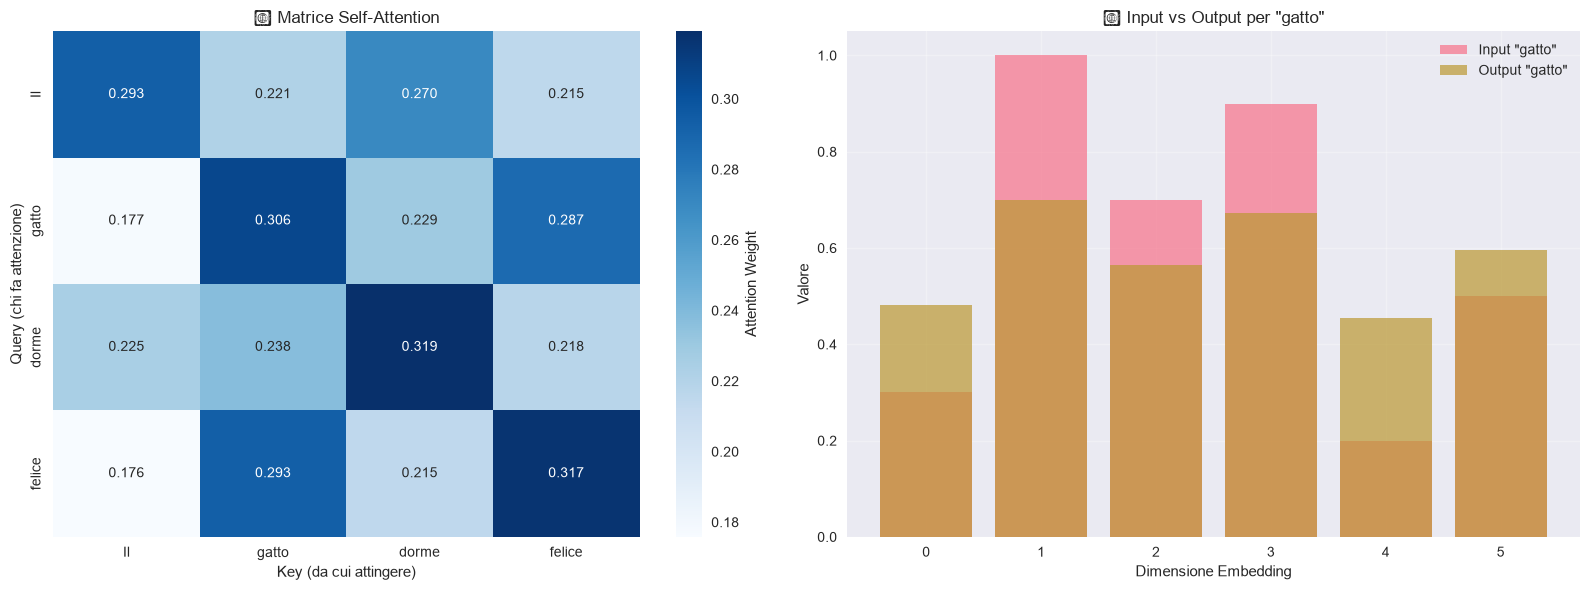


💡 INTERPRETAZIONE:

🔍 Analisi attention per 'gatto':
   Attenzione a 'Il': 0.177
   Attenzione a 'gatto': 0.306
   Attenzione a 'dorme': 0.229
   Attenzione a 'felice': 0.287

🎯 'gatto' fa più attenzione a: 'gatto'

📚 COSA SIGNIFICA:
   • Ogni parola 'guarda' tutte le altre parole
   • I pesi indicano quanto è importante ogni parola
   • L'output è una combinazione pesata di tutte le parole
   • Cattura relazioni semantiche e sintattiche

🔬 FORMULA SELF-ATTENTION:
   Attention(Q,K,V) = softmax(QK^T / √d_k)V
   Dove:
   • Q = Query (cosa cerco?)
   • K = Key (cosa ho?)
   • V = Value (cosa restituisco?)
   • d_k = dimensione delle chiavi (per stabilità numerica)

📊 SPIEGAZIONE DEL GRAFICO 'Input vs Output' (barre)

Il grafico confronta, dimensione per dimensione (0-5), il vettore
INPUT di 'gatto' con il suo vettore OUTPUT dopo la self-attention.

🔢 Come si ottiene OUTPUT[1]:
   Non è un valore nuovo 'inventato': è la somma pesata delle righe di V
   (qui V=X), usando i pesi della riga 

In [9]:
# ============================================================
# BLOCCO 3 — SELF-ATTENTION IMPLEMENTATA A MANO (numpy)
# ============================================================
# OBIETTIVO: mostrare passo per passo la formula
#     Attention(Q, K, V) = softmax(Q · K^T / sqrt(d_k)) · V
# usando solo numpy, senza nessun framework di deep learning e senza
# nessun training. E' un esempio di ALGEBRA LINEARE, non un modello
# che ha imparato qualcosa.
# ============================================================
print("🎯 SELF-ATTENTION: IL CUORE DEI TRANSFORMER\n")

class SelfAttention:
    def __init__(self, d_model):
        """Inizializza Self-Attention

        Args:
            d_model: Dimensione del modello (embedding size)
        """
        # d_model = dimensione del vettore che rappresenta ogni parola
        # (l'"embedding size" di tutto il blocco: qui seq_len parole,
        # ognuna un vettore di d_model numeri, es. X.shape = (4, 6)).
        self.d_model = d_model
        # d_k = dimensione dei vettori query/key: lo spazio in cui Q e K
        # vengono confrontati col prodotto scalare (e con cui si scala
        # la formula, /sqrt(d_k), per stabilita numerica). Qui W_q/W_k
        # sono l'identita (nessuna vera proiezione), quindi d_k coincide
        # semplicemente con d_model (nel Blocco 4, con piu teste, sara
        # invece d_model // num_heads: una fetta piu piccola per testa).
        self.d_k = d_model  # Dimensione delle chiavi

        # --------------------------------------------------------
        # SEMPLIFICAZIONE DIDATTICA IMPORTANTE:
        # In un vero Transformer, W_q/W_k/W_v sono matrici APPRESE
        # durante il training (i "pesi" del modello). Qui sono invece
        # fissate come matrice identità: moltiplicare X per l'identità
        # non lo cambia, quindi avremo Q = K = V = X. Questo isola e
        # mostra SOLO il meccanismo dell'attention, senza la
        # complicazione di pesi appresi (che qui non esistono).
        # --------------------------------------------------------
        self.W_q = np.eye(d_model)  # Query  -> nessun apprendimento, è l'identità
        self.W_k = np.eye(d_model)  # Key    -> nessun apprendimento, è l'identità
        self.W_v = np.eye(d_model)  # Value  -> nessun apprendimento, è l'identità

    def scaled_dot_product_attention(self, Q, K, V, mask=None):
        """Calcola Scaled Dot-Product Attention

        Args:
            Q: Query matrix (seq_len, d_k)
            K: Key matrix (seq_len, d_k)
            V: Value matrix (seq_len, d_v)
            mask: Maschera opzionale
        """
        # Step 1: scores[i, j] = quanto la query della parola i è
        # "compatibile" con la key della parola j (prodotto scalare).
        # Shape: (seq_len, seq_len).
        scores = np.dot(Q, K.T)

        # Step 2: scala per sqrt(d_k) -> evita che i numeri crescano
        # troppo (e la softmax "saturi") quando d_k è grande. E' solo
        # stabilità numerica, non è apprendimento.
        scores = scores / np.sqrt(self.d_k)

        # Step 3: se presente una maschera, azzera (con -inf) le
        # posizioni non permesse PRIMA della softmax, così dopo la
        # softmax quelle posizioni avranno peso ~0.
        # Questo notebook non passa mai una maschera qui: per questo la
        # self-attention "a mano" resta bidirezionale (guarda avanti e
        # indietro), come vedremo di nuovo nel Blocco 5.
        if mask is not None:
            scores = np.where(mask == 0, -1e9, scores)

        # Step 4: softmax riga per riga -> trasforma gli score in pesi
        # che sommano a 1 per ogni query.
        attention_weights = self.softmax(scores)

        # Step 5: l'output è una MEDIA PESATA delle righe di V, usando
        # i pesi appena calcolati. Shape: (seq_len, d_v).
        output = np.dot(attention_weights, V)
        #scores[i,j] = np.dot(Q[i], K[j]) alto vuol dire "il vettore query della parola i è molto simile/allineato al v
        # vettore key della parola j" → quella parola è rilevante per l'attention.

        return output, attention_weights

    def softmax(self, x):
        """
        Applica la Softmax riga per riga.
        Ogni riga rappresenta una Query e viene trasformata
        in un insieme di pesi di attenzione che sommano a 1.
        """
        # Sottraiamo il massimo di ogni riga prima di esponenziare:
        # stesso risultato matematico, ma evita overflow numerico.
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        # Normalizziamo: ogni riga somma esattamente a 1.
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        """Forward pass dell'attention

        Args:
            X: Input embeddings (seq_len, d_model)
        """
        # Con W_q=W_k=W_v=identità, questo equivale a Q=K=V=X.
        Q = np.dot(X, self.W_q)
        K = np.dot(X, self.W_k)
        V = np.dot(X, self.W_v)

        output, attention_weights = self.scaled_dot_product_attention(Q, K, V)

        return output, attention_weights

# ================================================================
# TEST: eseguiamo davvero il codice sopra su una sequenza di esempio
# ================================================================
print("🧪 TEST SELF-ATTENTION:\n")

seq_len = 4    # 4 parole nella frase di esempio
d_model = 6    # ogni parola è rappresentata da un vettore di 6 numeri

# Embedding SCRITTI A MANO (non appresi, non veri): servono solo per
# avere numeri concreti su cui vedere l'attention funzionare.
X = np.array([
    [1.0, 0.5, 0.2, 0.1, 0.8, 0.3],  # "Il"
    [0.3, 1.0, 0.7, 0.9, 0.2, 0.5],  # "gatto"
    [0.8, 0.2, 1.0, 0.4, 0.6, 0.7],  # "dorme"
    [0.1, 0.9, 0.3, 1.0, 0.4, 0.8]   # "felice"
])

parole = ["Il", "gatto", "dorme", "felice"]

print(f"📝 SEQUENZA: {' '.join(parole)}")
print(f"📊 INPUT SHAPE: {X.shape} (seq_len={seq_len}, d_model={d_model})")

# Creiamo l'oggetto SelfAttention (con W_q=W_k=W_v=identità come spiegato sopra).
attention = SelfAttention(d_model)

# Forward pass VERO: eseguiamo davvero i 5 step della formula su X.
output, attention_weights = attention.forward(X)

print(f"\n📈 OUTPUT SHAPE: {output.shape}")
print(f"🎯 ATTENTION WEIGHTS SHAPE: {attention_weights.shape}")

# La matrice di attention è (4,4): riga i = quanto la parola i guarda
# ciascuna delle 4 parole (i pesi di ogni riga sommano a 1).
print("\n🔍 ATTENTION WEIGHTS MATRIX:")
df_attention = pd.DataFrame(attention_weights, index=parole, columns=parole)
print(df_attention.round(3))

# Visualizzazione grafica
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap dei pesi di attention: più scuro = più attenzione.
sns.heatmap(attention_weights,
            xticklabels=parole,
            yticklabels=parole,
            annot=True, fmt='.3f',
            cmap='Blues', ax=ax1,
            cbar_kws={'label': 'Attention Weight'})
ax1.set_title('🎯 Matrice Self-Attention')
ax1.set_xlabel('Key (da cui attingere)')
ax1.set_ylabel('Query (chi fa attenzione)')

# Confrontiamo l'embedding di INPUT di "gatto" con il suo OUTPUT dopo
# l'attention: l'output è una combinazione pesata dei Value (che qui
# coincidono con gli input originali, essendo V=X).
parola_focus = 1  # "gatto"

ax2.bar(range(d_model), X[parola_focus], alpha=0.7, label=f'Input "{parole[parola_focus]}"')
ax2.bar(range(d_model), output[parola_focus], alpha=0.7, label=f'Output "{parole[parola_focus]}"')
ax2.set_title(f'📊 Input vs Output per "{parole[parola_focus]}"')
ax2.set_xlabel('Dimensione Embedding')
ax2.set_ylabel('Valore')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# INTERPRETAZIONE dei numeri ottenuti (non solo teoria: sono i VERI
# valori calcolati sopra da questa esecuzione)
# ================================================================
print("\n💡 INTERPRETAZIONE:")
print(f"\n🔍 Analisi attention per '{parole[parola_focus]}':")
for i, parola in enumerate(parole):
    weight = attention_weights[parola_focus, i]
    print(f"   Attenzione a '{parola}': {weight:.3f}")

max_attention_idx = np.argmax(attention_weights[parola_focus])
print(f"\n🎯 '{parole[parola_focus]}' fa più attenzione a: '{parole[max_attention_idx]}'")

print("\n📚 COSA SIGNIFICA:")
print("   • Ogni parola 'guarda' tutte le altre parole")
print("   • I pesi indicano quanto è importante ogni parola")
print("   • L'output è una combinazione pesata di tutte le parole")
print("   • Cattura relazioni semantiche e sintattiche")

print("\n🔬 FORMULA SELF-ATTENTION:")
print("   Attention(Q,K,V) = softmax(QK^T / √d_k)V")
print("   Dove:")
print("   • Q = Query (cosa cerco?)")
print("   • K = Key (cosa ho?)")
print("   • V = Value (cosa restituisco?)")
print("   • d_k = dimensione delle chiavi (per stabilità numerica)")

print("\n" + "=" * 60)
print("📊 SPIEGAZIONE DEL GRAFICO 'Input vs Output' (barre)")
print("=" * 60)
print(f"\nIl grafico confronta, dimensione per dimensione (0-{d_model-1}), il vettore")
print(f"INPUT di '{parole[parola_focus]}' con il suo vettore OUTPUT dopo la self-attention.")

print(f"\n🔢 Come si ottiene OUTPUT[{parola_focus}]:")
print("   Non è un valore nuovo 'inventato': è la somma pesata delle righe di V")
print("   (qui V=X), usando i pesi della riga corrispondente della matrice di attention:")
print(f"   output[{parola_focus}] = Σ_j attention_weights[{parola_focus}, j] · X[j]")

print("\n📐 Confronto dimensione per dimensione:")
for i in range(d_model):
    diff = output[parola_focus, i] - X[parola_focus, i]
    freccia = "↑" if diff > 0 else ("↓" if diff < 0 else "=")
    print(f"   dim {i}: input={X[parola_focus, i]:.3f}  →  output={output[parola_focus, i]:.3f}   ({freccia} {diff:+.3f})")

print("\n💡 Interpretazione:")
print(f"   • Dove le due barre sono quasi uguali, quella dimensione di '{parole[parola_focus]}' era già simile")
print("     a quella delle parole cui presta attenzione: l'attention 'conferma' il valore originale.")
print(f"   • Dove divergono di più, la self-attention ha spostato quella dimensione verso il valore")
print(f"     della parola con peso maggiore (qui '{parole[max_attention_idx]}'), mescolando il contesto")
print("     della frase dentro l'embedding originale.")
print("   • Questo è l'effetto centrale della self-attention: ogni parola smette di essere un vettore")
print("     isolato e diventa una combinazione pesata (contestuale) di tutta la frase.")

## 🏗️ Blocco 4 — Multi-Head Attention

**🔗 Legame col blocco precedente:** `MultiHeadAttention` ripete esattamente gli stessi 5 step della
`SelfAttention` del Blocco 3, `num_heads` volte (qui 2) in parallelo — ma con una differenza: le matrici
`W_q`/`W_k`/`W_v` qui sono inizializzate **a caso** (`np.random.randn`), non a identità. Restano comunque
**mai aggiornate**: non c'è training né in questo blocco né nel precedente.

**🔍 Cosa viene fatto realmente:** vengono calcolate 2 attention indipendenti (una per testa), ciascuna con le
proprie proiezioni casuali, poi gli output vengono concatenati e riproiettati con `W_o`. Le due heatmap
mostrano i pesi VERI di questa esecuzione — sono diverse tra loro solo perché partono da matrici random
diverse, **non** perché una testa ha "imparato" a specializzarsi su sintassi o semantica (quello richiederebbe
training, che qui non avviene).

**🎯 Obiettivo:** mostrare come più "teste" di attention indipendenti, calcolate in parallelo, si combinano in
un'unica Multi-Head Attention — il componente che useremo (questa volta nella versione ufficiale di Keras) nel
Blocco 5.

🏗️ MULTI-HEAD ATTENTION

🧪 TEST MULTI-HEAD ATTENTION:

📊 CONFIGURAZIONE:
   d_model: 8
   num_heads: 2
   d_k per testa: 4
   Sequenza: Il gatto nero dorme

📈 RISULTATI:
   Input shape: (4, 8)
   Output shape: (4, 8)
   Numero teste: 2


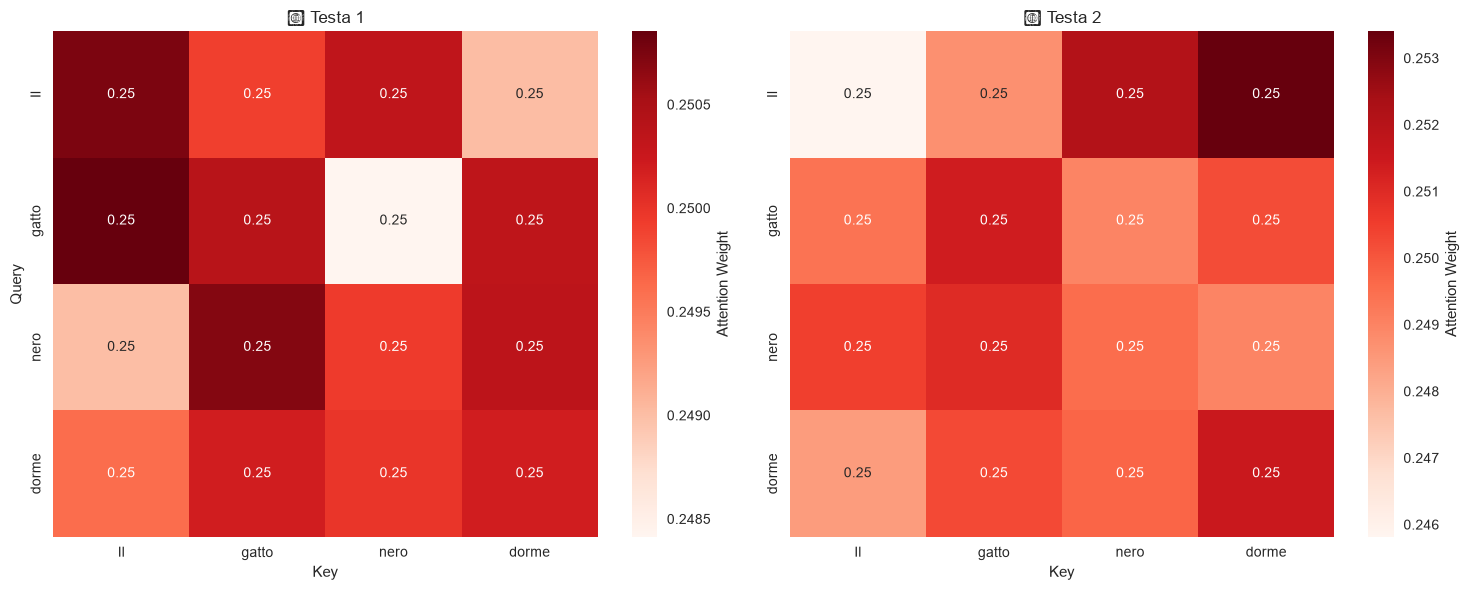


🔍 ANALISI DELLE TESTE:

🎯 Testa 1:
   Connessione più forte: 'gatto' → 'Il' (0.251)
   Parola più 'attenta': 'Il' (avg: 0.250)

🎯 Testa 2:
   Connessione più forte: 'Il' → 'dorme' (0.253)
   Parola più 'attenta': 'Il' (avg: 0.250)

💡 VANTAGGI MULTI-HEAD (concetto teorico — qui non verificabile perché non c'è training):
   🎭 Diverse teste catturano diversi tipi di relazioni
   📍 Una testa può focalizzarsi su sintassi, un'altra su semantica
   🔄 Parallelizzazione efficiente
   🎯 Maggiore capacità espressiva
   🔍 Ridondanza e robustezza

🔬 ESEMPI DI SPECIALIZZAZIONE (in un modello VERO e ADDESTRATO — non in questo notebook):
   • Testa 1: Relazioni sintattiche (soggetto-verbo)
   • Testa 2: Relazioni semantiche (aggettivo-nome)
   • Testa 3: Dipendenze a lungo raggio
   • Testa 4: Correference resolution

📐 FORMULA MULTI-HEAD:
   MultiHead(Q,K,V) = Concat(head₁,...,headₕ)W^O
   dove headᵢ = Attention(QWᵢ^Q, KWᵢ^K, VWᵢ^V)


In [10]:
# ============================================================
# BLOCCO 4 — MULTI-HEAD ATTENTION (numpy)
# ============================================================
# LEGAME COL BLOCCO PRECEDENTE: questa classe ripete esattamente gli
# stessi 5 step della SelfAttention del Blocco 3, num_heads volte in
# parallelo, ognuna con proprie matrici di proiezione, e poi ricombina
# i risultati. E' lo stesso "motore", replicato e concatenato.
#
# DIFFERENZA IMPORTANTE rispetto al Blocco 3: qui W_q/W_k/W_v NON sono
# identità, ma matrici RANDOM (np.random.randn). Anche questo però non
# è apprendimento: sono numeri casuali generati una volta e mai
# aggiornati (nessun training, nessun gradiente, nessun optimizer).
# ============================================================
print("🏗️ MULTI-HEAD ATTENTION\n")

class MultiHeadAttention:
    def __init__(self, d_model, num_heads):
        """Inizializza Multi-Head Attention

        Args:
            d_model: Dimensione del modello
            num_heads: Numero di teste di attention
        """
        assert d_model % num_heads == 0  # d_model deve dividersi esattamente tra le teste

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads  # dimensione riservata a ciascuna testa

        # Matrici di proiezione RANDOM per ciascuna testa (mai allenate).
        # Shape: (num_heads, d_model, d_k) -> una matrice diversa per ogni testa.
        self.W_q = np.random.randn(num_heads, d_model, self.d_k) * 0.1
        self.W_k = np.random.randn(num_heads, d_model, self.d_k) * 0.1
        self.W_v = np.random.randn(num_heads, d_model, self.d_k) * 0.1

        # Matrice di output finale: ricombina le teste concatenate
        # riportandole alla dimensione originale d_model.
        self.W_o = np.random.randn(d_model, d_model) * 0.1

    def scaled_dot_product_attention(self, Q, K, V):
        """Attention per una singola testa — identica alla logica del Blocco 3."""
        scores = np.dot(Q, K.T) / np.sqrt(self.d_k)
        attention_weights = self.softmax(scores)
        output = np.dot(attention_weights, V)
        return output, attention_weights

    def softmax(self, x):
        """Softmax numericamente stabile (stessa implementazione del Blocco 3)."""
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        """Forward pass Multi-Head Attention

        Args:
            X: Input (seq_len, d_model)
        """
        seq_len = X.shape[0]
        head_outputs = []
        all_attention_weights = []

        # Ogni testa lavora in modo completamente indipendente dalle altre:
        # proietta X con le proprie W_q/W_k/W_v e calcola la propria attention.
        for h in range(self.num_heads):
            Q_h = np.dot(X, self.W_q[h])  # (seq_len, d_k) — proiezione SOLO di questa testa
            K_h = np.dot(X, self.W_k[h])
            V_h = np.dot(X, self.W_v[h])

            head_output, attention_weights = self.scaled_dot_product_attention(Q_h, K_h, V_h)

            head_outputs.append(head_output)
            all_attention_weights.append(attention_weights)

        # Concateniamo gli output delle teste lungo l'asse delle feature:
        # da num_heads matrici (seq_len, d_k) a una sola (seq_len, d_model).
        concatenated = np.concatenate(head_outputs, axis=1)

        # Proiezione finale: mescola l'informazione delle diverse teste.
        output = np.dot(concatenated, self.W_o)

        return output, all_attention_weights

# ================================================================
# TEST: eseguiamo davvero il codice sopra
# ================================================================
print("🧪 TEST MULTI-HEAD ATTENTION:\n")

d_model = 8
num_heads = 2
seq_len = 4

# Input casuale (non un vero embedding appreso, solo numeri di esempio).
X_multi = np.random.randn(seq_len, d_model) * 0.5
parole_multi = ["Il", "gatto", "nero", "dorme"]

print(f"📊 CONFIGURAZIONE:")
print(f"   d_model: {d_model}")
print(f"   num_heads: {num_heads}")
print(f"   d_k per testa: {d_model // num_heads}")
print(f"   Sequenza: {' '.join(parole_multi)}")

mha = MultiHeadAttention(d_model, num_heads)
output_multi, all_attention_weights = mha.forward(X_multi)

print(f"\n📈 RISULTATI:")
print(f"   Input shape: {X_multi.shape}")
print(f"   Output shape: {output_multi.shape}")
print(f"   Numero teste: {len(all_attention_weights)}")

# Una heatmap per ogni testa: essendo i pesi random e non allenati, le
# due heatmap saranno diverse tra loro solo perché partono da matrici
# di proiezione diverse — non perché una testa ha "imparato" qualcosa
# di specifico (sintassi, semantica, ecc.).
fig, axes = plt.subplots(1, num_heads, figsize=(15, 6))
if num_heads == 1:
    axes = [axes]

for h in range(num_heads):
    sns.heatmap(all_attention_weights[h],
                xticklabels=parole_multi,
                yticklabels=parole_multi,
                annot=True, fmt='.2f',
                cmap='Reds', ax=axes[h],
                cbar_kws={'label': 'Attention Weight'})
    axes[h].set_title(f'🎯 Testa {h+1}')
    axes[h].set_xlabel('Key')
    if h == 0:
        axes[h].set_ylabel('Query')

plt.tight_layout()
plt.show()

# Analisi delle teste: valori VERI di questa esecuzione, ma senza un
# significato linguistico garantito, perché i pesi sono random.
print("\n🔍 ANALISI DELLE TESTE:")
for h in range(num_heads):
    print(f"\n🎯 Testa {h+1}:")
    attention_matrix = all_attention_weights[h]

    max_positions = np.unravel_index(np.argmax(attention_matrix), attention_matrix.shape)
    max_value = attention_matrix[max_positions]

    print(f"   Connessione più forte: '{parole_multi[max_positions[0]]}' → '{parole_multi[max_positions[1]]}' ({max_value:.3f})")

    avg_attention = np.mean(attention_matrix, axis=1)
    most_attended = np.argmax(avg_attention)
    print(f"   Parola più 'attenta': '{parole_multi[most_attended]}' (avg: {avg_attention[most_attended]:.3f})")

print("\n💡 VANTAGGI MULTI-HEAD (concetto teorico — qui non verificabile perché non c'è training):")
vantaggi_mh = [
    "🎭 Diverse teste catturano diversi tipi di relazioni",
    "📍 Una testa può focalizzarsi su sintassi, un'altra su semantica",
    "🔄 Parallelizzazione efficiente",
    "🎯 Maggiore capacità espressiva",
    "🔍 Ridondanza e robustezza"
]

for vantaggio in vantaggi_mh:
    print(f"   {vantaggio}")

print("\n🔬 ESEMPI DI SPECIALIZZAZIONE (in un modello VERO e ADDESTRATO — non in questo notebook):")
print("   • Testa 1: Relazioni sintattiche (soggetto-verbo)")
print("   • Testa 2: Relazioni semantiche (aggettivo-nome)")
print("   • Testa 3: Dipendenze a lungo raggio")
print("   • Testa 4: Correference resolution")

print("\n📐 FORMULA MULTI-HEAD:")
print("   MultiHead(Q,K,V) = Concat(head₁,...,headₕ)W^O")
print("   dove headᵢ = Attention(QWᵢ^Q, KWᵢ^K, VWᵢ^V)")


## 🏛️ Blocco 5a — Definizione dell'architettura Transformer (classi Keras)

**🔗 Legame col blocco precedente:** qui **non riusiamo** le classi numpy scritte a mano nei Blocchi 3-4.
Usiamo invece i layer ufficiali di Keras (`layers.MultiHeadAttention`, `layers.Dense`,
`layers.LayerNormalization`, `layers.Embedding`): livelli neurali VERI, con pesi che il framework sa
aggiornare tramite backpropagation — cosa che le classi numpy non sapevano fare. Concettualmente, però, il
meccanismo di attention dentro `layers.MultiHeadAttention` è lo stesso identificato nei Blocchi 3-4.

**🔍 Cosa viene fatto in questa parte:** definiamo SOLO le classi che compongono l'architettura —
`PositionalEncoding` (aggiunge informazione di posizione con seno/coseno, senza pesi allenabili) e
`TransformerBlock` (Multi-Head Attention → residuo + LayerNorm → Feed-Forward → residuo + LayerNorm),
impilati `num_layers` volte dentro `SimpleTransformer`. **Non costruiamo ancora nessun modello concreto e
non eseguiamo nessun calcolo**: la costruzione e il test avvengono nella parte **5b**, subito dopo.

**🎯 Obiettivo:** avere pronto uno stack Transformer completo (non solo il meccanismo di attention isolato,
ma un intero modello con embedding, posizione, attention, feed-forward, residui, normalizzazione).

In [11]:
# ============================================================
# BLOCCO 5A — DEFINIZIONE DELL'ARCHITETTURA (classi Keras)
# ============================================================
# In questa prima parte del Blocco 5 definiamo SOLO le classi che
# compongono un Transformer completo. Non costruiamo ancora nessun
# modello e non eseguiamo nessun calcolo: qui scriviamo il "progetto"
# dell'architettura, che useremo e testeremo nella parte 5B.
#
# Le tre classi, dalla più semplice alla più completa:
#   1. PositionalEncoding — nessun peso allenabile, solo una formula
#      matematica fissa che "marca" la posizione di ogni token.
#   2. TransformerBlock   — UN singolo blocco encoder (attention +
#      feed-forward + residui + normalizzazione), con pesi VERI.
#   3. SimpleTransformer  — impila più TransformerBlock uno sopra
#      l'altro, dopo embedding + positional encoding, con una
#      proiezione finale sul vocabolario.
# ============================================================

class PositionalEncoding(layers.Layer):
    """Positional Encoding per Transformer.

    Non ha pesi da allenare: è una formula matematica fissa (seno/coseno)
    che serve a "marcare" ogni posizione della sequenza, perché la
    self-attention da sola non distingue l'ordine delle parole (guarda
    tutte le posizioni alla pari, senza sapere quale viene prima o dopo).
    """

    def __init__(self, max_len=5000, d_model=512):
        super().__init__()
        self.d_model = d_model

        # Costruiamo una matrice (max_len, d_model): una "riga" diversa
        # per ogni possibile posizione nella sequenza. max_len è la
        # lunghezza massima di sequenza che vogliamo poter codificare;
        # d_model è la stessa dimensione usata per gli embedding, perché
        # la codifica di posizione verrà SOMMATA all'embedding (le due
        # cose devono avere la stessa forma per potersi sommare).
        pe = np.zeros((max_len, d_model))
        position = np.arange(0, max_len)[:, np.newaxis]  # colonna: 0,1,2,...,max_len-1

        # div_term contiene una frequenza diversa per ogni coppia di
        # dimensioni (0-1, 2-3, 4-5, ...): dimensioni "vicine" nell'indice
        # oscillano più lentamente, quelle più avanti più velocemente.
        # È la stessa formula del paper originale "Attention Is All You Need".
        div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))

        # Dimensioni pari -> seno, dimensioni dispari -> coseno, entrambe
        # calcolate su posizione * frequenza. Il risultato: posizioni
        # vicine nella sequenza avranno codifiche simili tra loro,
        # posizioni lontane codifiche più diverse — esattamente quello
        # che serve per "sentire" la distanza tra i token.
        pe[:, 0::2] = np.sin(position * div_term)
        pe[:, 1::2] = np.cos(position * div_term)

        # tf.constant: è un tensore FISSO, non un peso; il training (se
        # ci fosse) non lo modificherebbe mai.
        self.pe = tf.constant(pe, dtype=tf.float32)

    def call(self, x):
        # x ha forma (batch_size, seq_len, d_model). Ci serve solo la
        # codifica delle prime seq_len posizioni (le altre righe di
        # self.pe, oltre seq_len, non servono per questo input).
        seq_len = tf.shape(x)[1]
        # Sommiamo la codifica di posizione direttamente all'embedding:
        # self.pe[:seq_len, :] ha forma (seq_len, d_model) e viene
        # "broadcastato" automaticamente su tutto il batch.
        return x + self.pe[:seq_len, :]

class TransformerBlock(layers.Layer):
    """UN blocco Transformer (di tipo ENCODER).

    Composto da: Multi-Head Attention -> residuo -> LayerNorm ->
    Feed-Forward -> residuo -> LayerNorm. Ha pesi VERI e allenabili.
    """

    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1):
        super().__init__()
        self.d_model = d_model      # dimensione dei vettori che scorrono nel blocco
        self.num_heads = num_heads  # quante "teste" di attention in parallelo

        # Multi-Head Attention UFFICIALE di Keras (non quella scritta a
        # mano nel Blocco 4): ha pesi veri e supporta il training.
        # key_dim = d_model // num_heads: ogni testa lavora su una "fetta"
        # più piccola dello spazio, così il costo totale resta ~d_model
        # anche aumentando il numero di teste.
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout_rate
        )

        # Feed-Forward Network: due Dense, con una non-linearità (ReLU)
        # in mezzo. Applicato a ogni posizione indipendentemente (non
        # mescola informazioni tra posizioni diverse, a differenza
        # dell'attention: qui ogni token viene "elaborato" per conto suo).
        # dff (di solito più grande di d_model) è la dimensione "nascosta"
        # interna di questa trasformazione.
        self.ffn = tf.keras.Sequential([
            layers.Dense(dff, activation='relu'),
            layers.Dense(d_model)   # torna alla dimensione originale, per poter fare il residuo
        ])

        # Layer Normalization: normalizza i valori (media 0, varianza 1)
        # lungo l'ultima dimensione, per stabilizzare i numeri durante il
        # training. Ne servono due: una dopo l'attention, una dopo il feed-forward.
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)

        # Dropout: durante il training spegne (mette a zero) una parte
        # casuale dei valori, per evitare che il modello "memorizzi"
        # troppo i dati di training. Durante l'inferenza (training=False)
        # non ha alcun effetto.
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, x, training=False):
        # --------------------------------------------------------
        # PUNTO CHIAVE — perché questo è un ENCODER:
        # self.mha(x, x, x, ...) usa la STESSA x come query, key e
        # value, e non passiamo NESSUNA maschera causale. Questo
        # significa che ogni posizione della sequenza vede liberamente
        # TUTTE le altre posizioni, incluse quelle "future". Un vero
        # decoder autoregressivo (come GPT-2, Blocco 6) impedirebbe
        # invece a ogni posizione di vedere le posizioni successive.
        # --------------------------------------------------------
        attn_output = self.mha(x, x, x, training=training)
        attn_output = self.dropout1(attn_output, training=training)
        # Connessione residua: sommiamo l'input originale x all'output
        # dell'attention, PRIMA di normalizzare. Il residuo aiuta il
        # gradiente a "passare" anche attraverso i blocchi profondi,
        # rendendo il training più stabile.
        out1 = self.layernorm1(x + attn_output)

        # Stesso schema per il feed-forward: trasformazione, dropout,
        # residuo (rispetto a out1, non al x originale), normalizzazione.
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        out2 = self.layernorm2(out1 + ffn_output)

        return out2

class SimpleTransformer(tf.keras.Model):
    """Transformer semplificato: impila più TransformerBlock uno sopra
    l'altro, dopo embedding + positional encoding, con un output finale
    proiettato su tutto il vocabolario.

    E' un'architettura VERA e in linea di principio allenabile — ma in
    questo notebook non viene mai addestrata (lo facciamo nella parte 5B,
    solo a livello di test delle dimensioni).
    """

    def __init__(self, vocab_size, d_model, num_heads, num_layers, dff, max_len=1000, dropout_rate=0.1):
        super().__init__()
        self.d_model = d_model
        self.vocab_size = vocab_size

        # Trasforma ogni ID di token (un intero) in un vettore denso di
        # dimensione d_model: è la "tabella" che il modello impara,
        # una riga per ogni parola del vocabolario.
        self.embedding = layers.Embedding(vocab_size, d_model)

        # Aggiunge l'informazione di posizione (vedi classe sopra):
        # senza questo passaggio, il modello non saprebbe distinguere
        # "il gatto mangia il topo" da "il topo mangia il gatto".
        self.pos_encoding = PositionalEncoding(max_len, d_model)

        # Impiliamo num_layers blocchi identici nella struttura ma con
        # pesi indipendenti ciascuno: più layer = più capacità di
        # rappresentare relazioni complesse, a costo di più calcolo.
        self.transformer_blocks = [
            TransformerBlock(d_model, num_heads, dff, dropout_rate)
            for _ in range(num_layers)
        ]

        # Output: un punteggio (logit) per ogni parola del vocabolario,
        # per ogni posizione della sequenza.
        self.final_layer = layers.Dense(vocab_size)

        self.dropout = layers.Dropout(dropout_rate)

    def call(self, x, training=False):
        seq_len = tf.shape(x)[1]

        # 1) Embedding: da ID interi a vettori densi.
        x = self.embedding(x)
        # Scaliamo per sqrt(d_model): è una convenzione del paper
        # originale "Attention Is All You Need", che mantiene la
        # varianza dei valori sotto controllo prima di sommare la
        # positional encoding (che ha un'ampiezza fissa, indipendente da d_model).
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))

        # 2) Aggiungiamo l'informazione di posizione.
        x = self.pos_encoding(x)
        # 3) Dropout (attivo solo in training) prima di entrare nei blocchi.
        x = self.dropout(x, training=training)

        # 4) Passa in sequenza attraverso tutti i blocchi encoder: ogni
        # blocco raffina ulteriormente la rappresentazione dei token.
        for transformer_block in self.transformer_blocks:
            x = transformer_block(x, training=training)

        # 5) Proiezione finale sul vocabolario: un punteggio per ogni
        # parola possibile, per ogni posizione della sequenza.
        output = self.final_layer(x)

        return output

### ⚠️ Punto chiave per la lezione: questo è un ENCODER, non un decoder generativo

Guardate questa riga dentro `TransformerBlock.call`:

```python
attn_output = self.mha(x, x, x, training=training)
```

La stessa `x` è usata come query, key **e** value, e **non viene passata nessuna maschera causale**. Questo è
esattamente ciò che definisce un blocco **encoder**: ogni posizione vede liberamente **tutte** le altre
posizioni, incluse quelle "future" nella sequenza. Un vero **decoder autoregressivo** (come GPT-2, che vedremo
nel blocco successivo) applicherebbe invece una maschera che impedisce a ogni posizione di vedere le posizioni
successive.

Il `Dense(vocab_size)` finale può far pensare a un modello linguistico generativo, ma **senza maschera causale
non lo è**: architetturalmente questo è più vicino a uno stack di encoder (come BERT) con sopra una testa di
vocabolario.

## 🧩 Blocco 5a.2 — «Vera e allenabile» non vuol dire «già allenata»

Nel docstring di `SimpleTransformer` leggete:

> *E' un'architettura VERA e in linea di principio allenabile — ma in questo notebook non viene mai addestrata (lo facciamo nella parte 5B, solo a livello di test delle dimensioni).*

Vale la pena separare le due affermazioni.

### ✅ «Architettura VERA e allenabile» — cosa significa

Ogni layer che compone `SimpleTransformer` ha **pesi reali**, cioè variabili che TensorFlow aggiornerebbe con la backpropagation se lanciassimo un training:

- `layers.Embedding` — la tabella embedding (una riga per parola del vocabolario).
- `layers.MultiHeadAttention` dentro ogni `TransformerBlock` — le matrici di proiezione di query/key/value/output.
- Le due `layers.Dense` del feed-forward (`self.ffn`).
- `layers.LayerNormalization` — ha `gamma`/`beta` allenabili.
- `self.final_layer` — la proiezione finale sul vocabolario.

L'unica eccezione è `PositionalEncoding`: come visto nel Blocco 5a, è una formula fissa (seno/coseno), senza pesi. Tutto il resto sì.

Potete verificarlo voi stessi ispezionando `model.trainable_variables` dopo aver costruito il modello: non è vuoto.

### ❌ Cosa manca per un training VERO

Avere pesi allenabili non basta: per allenare davvero questo modello servirebbero cose che qui non costruiamo:

1. Una **loss function** (per un modello linguistico, tipicamente `sparse_categorical_crossentropy` per predire il token successivo).
2. Un **optimizer** (es. Adam) e una `model.compile(...)`.
3. Un **dataset** vero con coppie (input, target) — non i numeri casuali che useremo nel Blocco 5b.
4. Un ciclo di training (`model.fit(...)` oppure un loop manuale con `tf.GradientTape`), ripetuto per molte epoche.
5. Tempo e hardware sufficienti: anche un Transformer «piccolo» richiede GPU e molte iterazioni per convergere.

### 🔍 Cosa facciamo davvero nel Blocco 5b

Costruiamo un'istanza di `SimpleTransformer`, le passiamo un batch di ID casuali come input, e controlliamo **solo che la forma (shape) dell'output sia quella aspettata**: `(batch_size, seq_len, vocab_size)`.

Questo è un test strutturale (uno «smoke test» delle dimensioni): verifica che i layer siano collegati correttamente e che le dimensioni tornino — non che il modello impari qualcosa. È comunque un passaggio utile: se le shape non tornassero, lo scopriremmo qui, prima di provare ad allenare un modello che non funziona nemmeno «a vuoto».

## 🧪 Blocco 5b — Costruzione, test e visualizzazione del Transformer

**🔍 Cosa facciamo in questa seconda parte:** usiamo le classi definite nel Blocco 5a per costruire un
`SimpleTransformer` concreto, con iperparametri di esempio (`vocab_size`, `d_model`, `num_heads`, `num_layers`,
`dff`, ...). Lo testiamo passandogli un tensore di ID **casuali** (`tf.random.uniform`, non testo reale), solo
per verificare che le dimensioni dei tensori siano coerenti in ogni passaggio. Contiamo i parametri, stampiamo
la struttura (`.summary()`) e disegniamo uno schema dell'architettura.

**⚠️ Il modello non viene mai addestrato** (nessun `.compile()`/`.fit()`): i numeri nell'output non hanno alcun
significato linguistico, anche se i parametri contati da `count_params()` sono VERI parametri Keras (pesi
reali, solo non ancora allenati).

🏛️ ARCHITETTURA TRANSFORMER COMPLETA

🧪 TEST TRANSFORMER COMPLETO:

📊 CONFIGURAZIONE TRANSFORMER:
   Vocab size: 1,000
   Model dimension: 128
   Attention heads: 8
   Layers: 4
   FFN dimension: 512
   Max sequence length: 100

🔍 TEST INPUT:
   Shape: (2, 10)
   Sample: [687 289 761 786 692]...

📈 OUTPUT:
   Shape: (2, 10, 1000)
   Interpretazione: (batch_size, seq_len, vocab_size) — un punteggio per ogni parola del vocabolario, per ogni posizione, per ogni sequenza del batch

🔢 PARAMETRI TOTALI: 1,050,088
   (tutti VERI parametri Keras, ma inizializzati random e MAI aggiornati: nessun training è avvenuto)

🏗️ ARCHITETTURA:


Model: "simple_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (2, 10, 128)           │       128,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ ?                      │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ ?                      │       198,272 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ ?                      │       198,272 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ ?                      │       198,272 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_3             │ ?                      │       198,272 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (2, 10, 1000)          │       129,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,050,088 (4.01 MB)

 Trainable params: 1,050,088 (4.01 MB)

 Non-trainable params: 0 (0.00 B)

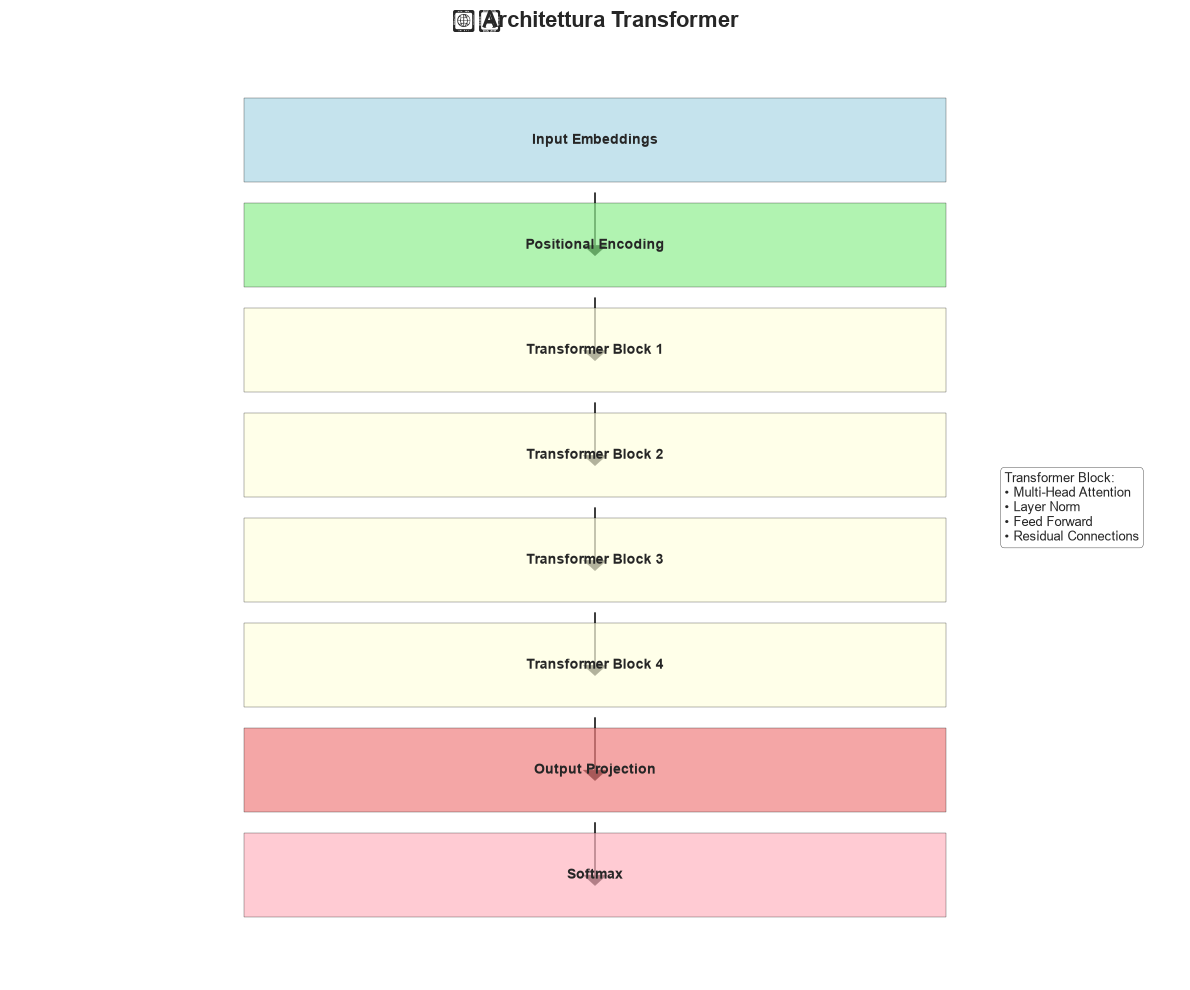


💡 COMPONENTI CHIAVE:
   📝 Input Embeddings: Converte token in vettori densi
   📍 Positional Encoding: Aggiunge informazione di posizione
   🎯 Multi-Head Attention: Cattura relazioni tra token (qui SENZA maschera causale -> encoder)
   🔄 Feed Forward: Trasformazione non-lineare
   🔗 Residual Connections: Facilita il training
   📏 Layer Normalization: Stabilizza il training
   📤 Output Projection: Mappa a vocabolario

🚀 VANTAGGI TRANSFORMER (in generale — questa istanza specifica non è addestrata):
   • Parallelizzazione completa
   • Cattura dipendenze a lungo raggio
   • Scalabile a sequenze molto lunghe
   • Transfer learning efficace
   • Architettura modulare e flessibile


In [12]:
# ============================================================
# BLOCCO 5B — COSTRUZIONE, TEST E VISUALIZZAZIONE
# ============================================================
# Usiamo le classi definite nel Blocco 5a per: costruire un modello
# concreto, testarlo con un input casuale (SOLO per controllare le
# shape), contare i parametri, stampare la struttura e visualizzare
# uno schema dell'architettura. NESSUN training avviene in questa cella.
# ============================================================
print("🏛️ ARCHITETTURA TRANSFORMER COMPLETA\n")
print("🧪 TEST TRANSFORMER COMPLETO:\n")

# --- Iperparametri di esempio (valori piccoli, solo a scopo didattico) ---
vocab_size = 1000     # quante parole diverse "conosce" il modello
d_model = 128         # dimensione dei vettori che scorrono nell'architettura
num_heads = 8         # numero di "teste" di attention in parallelo
num_layers = 4        # quanti TransformerBlock impilati
dff = 512             # dimensione nascosta del feed-forward interno
max_len = 100         # lunghezza massima di sequenza gestibile
dropout_rate = 0.1    # frazione di valori "spenti" durante il training

print(f"📊 CONFIGURAZIONE TRANSFORMER:")
print(f"   Vocab size: {vocab_size:,}")
print(f"   Model dimension: {d_model}")
print(f"   Attention heads: {num_heads}")
print(f"   Layers: {num_layers}")
print(f"   FFN dimension: {dff}")
print(f"   Max sequence length: {max_len}")

# Costruiamo il modello: a questo punto vengono creati tutti i layer
# (embedding, positional encoding, blocchi, output), ma i pesi sono
# ancora quelli inizializzati a caso da Keras — nessun training è avvenuto.
transformer = SimpleTransformer(
    vocab_size=vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    num_layers=num_layers,
    dff=dff,
    max_len=max_len,
    dropout_rate=dropout_rate
)

batch_size = 2   # quante sequenze testiamo insieme
seq_len = 10     # lunghezza di ciascuna sequenza di test
# Input FINTO: ID di token generati a caso (interi tra 0 e vocab_size-1),
# NON testo reale tokenizzato. Serve solo a "far girare" l'architettura.
test_input = tf.random.uniform((batch_size, seq_len), maxval=vocab_size, dtype=tf.int32)

print(f"\n🔍 TEST INPUT:")
print(f"   Shape: {test_input.shape}")
print(f"   Sample: {test_input[0].numpy()[:5]}...")

# Forward pass VERO (esegue davvero tutta l'architettura del Blocco 5a),
# ma su input casuale: serve solo a controllare che tutto "torni" a
# livello di dimensioni dei tensori, non a produrre testo sensato.
output = transformer(test_input, training=False)

print(f"\n📈 OUTPUT:")
print(f"   Shape: {output.shape}")
print(f"   Interpretazione: (batch_size, seq_len, vocab_size) — un punteggio per ogni parola del vocabolario, per ogni posizione, per ogni sequenza del batch")

# count_params() conta i pesi VERI creati da Keras (Embedding, Dense,
# MultiHeadAttention, LayerNormalization, ...): sono numeri reali, solo
# mai aggiornati da un training.
total_params = transformer.count_params()
print(f"\n🔢 PARAMETRI TOTALI: {total_params:,}")
print("   (tutti VERI parametri Keras, ma inizializzati random e MAI aggiornati: nessun training è avvenuto)")

print("\n🏗️ ARCHITETTURA:")
# build() "fissa" le shape di input, necessario perché summary() possa
# calcolare e mostrare correttamente la forma di ogni layer.
transformer.build(input_shape=(None, seq_len))
transformer.summary()

# Visualizzazione schematica dell'architettura: è solo un disegno con
# matplotlib (rettangoli e freccette), NON un nuovo calcolo del modello.
fig, ax = plt.subplots(figsize=(12, 10))

components = [
    ("Input Embeddings", 0.9, "lightblue"),
    ("Positional Encoding", 0.8, "lightgreen"),
    ("Transformer Block 1", 0.7, "lightyellow"),
    ("Transformer Block 2", 0.6, "lightyellow"),
    ("Transformer Block 3", 0.5, "lightyellow"),
    ("Transformer Block 4", 0.4, "lightyellow"),
    ("Output Projection", 0.3, "lightcoral"),
    ("Softmax", 0.2, "lightpink")
]

for i, (name, y_pos, color) in enumerate(components):
    rect = plt.Rectangle((0.2, y_pos-0.04), 0.6, 0.08,
                        facecolor=color, edgecolor='black', alpha=0.7)
    ax.add_patch(rect)
    ax.text(0.5, y_pos, name, ha='center', va='center',
           fontsize=10, fontweight='bold')
    if i < len(components) - 1:
        ax.arrow(0.5, y_pos-0.05, 0, -0.05, head_width=0.02, head_length=0.01,
                fc='black', ec='black')

ax.text(0.85, 0.55, 'Transformer Block:\n• Multi-Head Attention\n• Layer Norm\n• Feed Forward\n• Residual Connections',
        ha='left', va='center', fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

ax.set_xlim(0, 1)
ax.set_ylim(0.1, 1)
ax.axis('off')
ax.set_title('🏛️ Architettura Transformer', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n💡 COMPONENTI CHIAVE:")
componenti = [
    "📝 Input Embeddings: Converte token in vettori densi",
    "📍 Positional Encoding: Aggiunge informazione di posizione",
    "🎯 Multi-Head Attention: Cattura relazioni tra token (qui SENZA maschera causale -> encoder)",
    "🔄 Feed Forward: Trasformazione non-lineare",
    "🔗 Residual Connections: Facilita il training",
    "📏 Layer Normalization: Stabilizza il training",
    "📤 Output Projection: Mappa a vocabolario"
]

for componente in componenti:
    print(f"   {componente}")

print("\n🚀 VANTAGGI TRANSFORMER (in generale — questa istanza specifica non è addestrata):")
print("   • Parallelizzazione completa")
print("   • Cattura dipendenze a lungo raggio")
print("   • Scalabile a sequenze molto lunghe")
print("   • Transfer learning efficace")
print("   • Architettura modulare e flessibile")

**Riassumendo il Blocco 5 (5a + 5b):** architettura encoder-only (bidirezionale, nessuna maschera
causale) **definita** in 5a, **costruita e testata** in 5b solo con dati casuali. Non addestrato, non genera
mai una singola parola vera in questo notebook.

## 🤖 Blocco 6 — Large Language Models: qui usiamo un modello vero (GPT-2)

**🔗 Legame col blocco precedente:** **non riusiamo** `SimpleTransformer`/`TransformerBlock` del Blocco 5:
`GPT2LMHeadModel`/`GPT2Tokenizer` sono classi della libreria Hugging Face `transformers`, non del nostro
notebook. Concettualmente GPT-2 condivide gli stessi ingredienti (attention, feed-forward, residui, layer
norm) del Blocco 5, ma con due differenze cruciali: la sua self-attention è **mascherata/causale** (ogni
posizione vede solo le precedenti → è un **decoder**), e i suoi pesi sono **già addestrati** da OpenAI su
enormi quantità di testo — non inizializzati a caso.

**🔍 Cosa viene fatto realmente:**
- si caricano pesi VERI pre-addestrati con `.from_pretrained('gpt2')`;
- si genera DAVVERO nuovo testo con `model.generate(..., do_sample=True, temperature=0.8)` e poi di nuovo con
  `pipeline('text-generation', ...)` — **questo è l'UNICO metodo di decodifica realmente eseguito contro GPT-2**
  in tutto il notebook: non c'è mai `do_sample=False` (greedy puro), né `top_k=...`, né `top_p=...` passati al
  modello vero;
- i 4 grafici che seguono (greedy / temperature / top-k / nucleus) usano invece una distribuzione di
  probabilità **inventata** (`np.random.randn(vocab_size)` su un vocabolario finto di 20 token) — servono solo
  a illustrare visivamente COME funzionerebbe ciascuna strategia, non a mostrare gli output reali della
  generazione GPT-2 appena fatta sopra.

**🎯 Obiettivo:** mostrare un LLM vero, decoder-only e pre-addestrato che genera testo realmente, e introdurre
(concettualmente, tramite i grafici) le principali strategie di decodifica usate nella generazione di testo.

### 📊 Confronto diretto: Blocco 5 vs Blocco 6

| | Blocco 5 (`SimpleTransformer`, Keras) | Blocco 6 (GPT-2, Hugging Face) |
|---|---|---|
| Tipo di architettura | **Encoder-only** | **Decoder-only** |
| Self-attention | Bidirezionale (vede passato e futuro) | Causale/mascherata (vede solo il passato) |
| Addestramento | ❌ Nessuno (pesi casuali) | ✅ Pre-addestrato su enormi corpus di testo |
| Genera testo reale? | ❌ No (solo test di shape su numeri casuali) | ✅ Sì (`model.generate`, `pipeline`) |
| Metodi di decodifica REALMENTE usati | N/A (non genera nulla) | Solo sampling + temperature |
| Collegati tra loro nel codice? | No — sono due esempi indipendenti |

🤖 LARGE LANGUAGE MODELS (LLM)

📈 EVOLUZIONE DIMENSIONI LLM:
   2018: BERT Base    110M     - Bidirectional encoder
   2019: GPT-2        1.5B     - Autoregressive decoder
   2020: GPT-3        175B     - Few-shot learning
   2021: PaLM         540B     - Scaling laws
   2022: ChatGPT      ~175B    - RLHF tuning
   2023: GPT-4        ~1.7T    - Multimodal
   2024: Claude 3     ~1T+     - Long context

🧠 CARATTERISTICHE LLM MODERNI:
   📊 Miliardi/trilioni di parametri
   📚 Training su enormi corpus di testo
   🎯 Emergent abilities (capacità emergenti)
   🔄 In-context learning (few-shot)
   💬 Conversational abilities
   🧮 Reasoning e problem solving
   🌐 Multilingue e multimodale
   ⚡ Transfer learning efficace

🔬 ESPERIMENTO CON LLM PRE-ADDESTRATO:

📥 Caricamento GPT-2 small...


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1578.14it/s]


✅ Modello caricato con successo!

📊 INFORMAZIONI MODELLO:
   Nome: GPT-2 Small
   Parametri: 124,439,808
   Vocabolario: 50,257 token
   Contesto massimo: 1024 token

🎨 TEST DI GENERAZIONE:

🎯 Prompt 1: 'The future of artificial intelligence is'
   Generazione 1: The future of artificial intelligence is uncertain," said Charles Stadler, president of AI research firm Kaspersky Lab. "It's hard to say what future can come from that
   Generazione 2: The future of artificial intelligence is bound to come down to what happens once it happens. The goal is for it to be able to think what it thinks and it will be able to
--------------------------------------------------------------------------------
🎯 Prompt 2: 'In a world where robots and humans coexist,'
   Generazione 1: In a world where robots and humans coexist, it's hard to imagine a better time for a company like ours to go public. We have a clear path to getting there, and if we can
   Generazione 2: In a world where robots and humans

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 2687.67it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences', 'temperature', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


📝 GENERAZIONE CON PIPELINE:

🎯 Prompt: 'Artificial intelligence will'


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   1. Artificial intelligence will not only help us solve the problems of everyday life, but will also help us solve problems that we will never have the time to solve. It will be a good thing that the people who are not working on artificial intelligence have time to solve problems that we will never have the time to solve, including the problems in the Internet of Things (IoT).

In the future, artificial intelligence will become something that can solve problems of life. So, it will be very important that the people who are not working on artificial intelligence are able to do their work to solve these problems.

So, it is very important that the people who are not working on artificial intelligence are able to solve these problems. And, they will be able to build things that are in line with the needs of the people who are developing it.

The people who are not working on artificial intelligence are not going to have the time to do their work in order to solve these problems. It is 

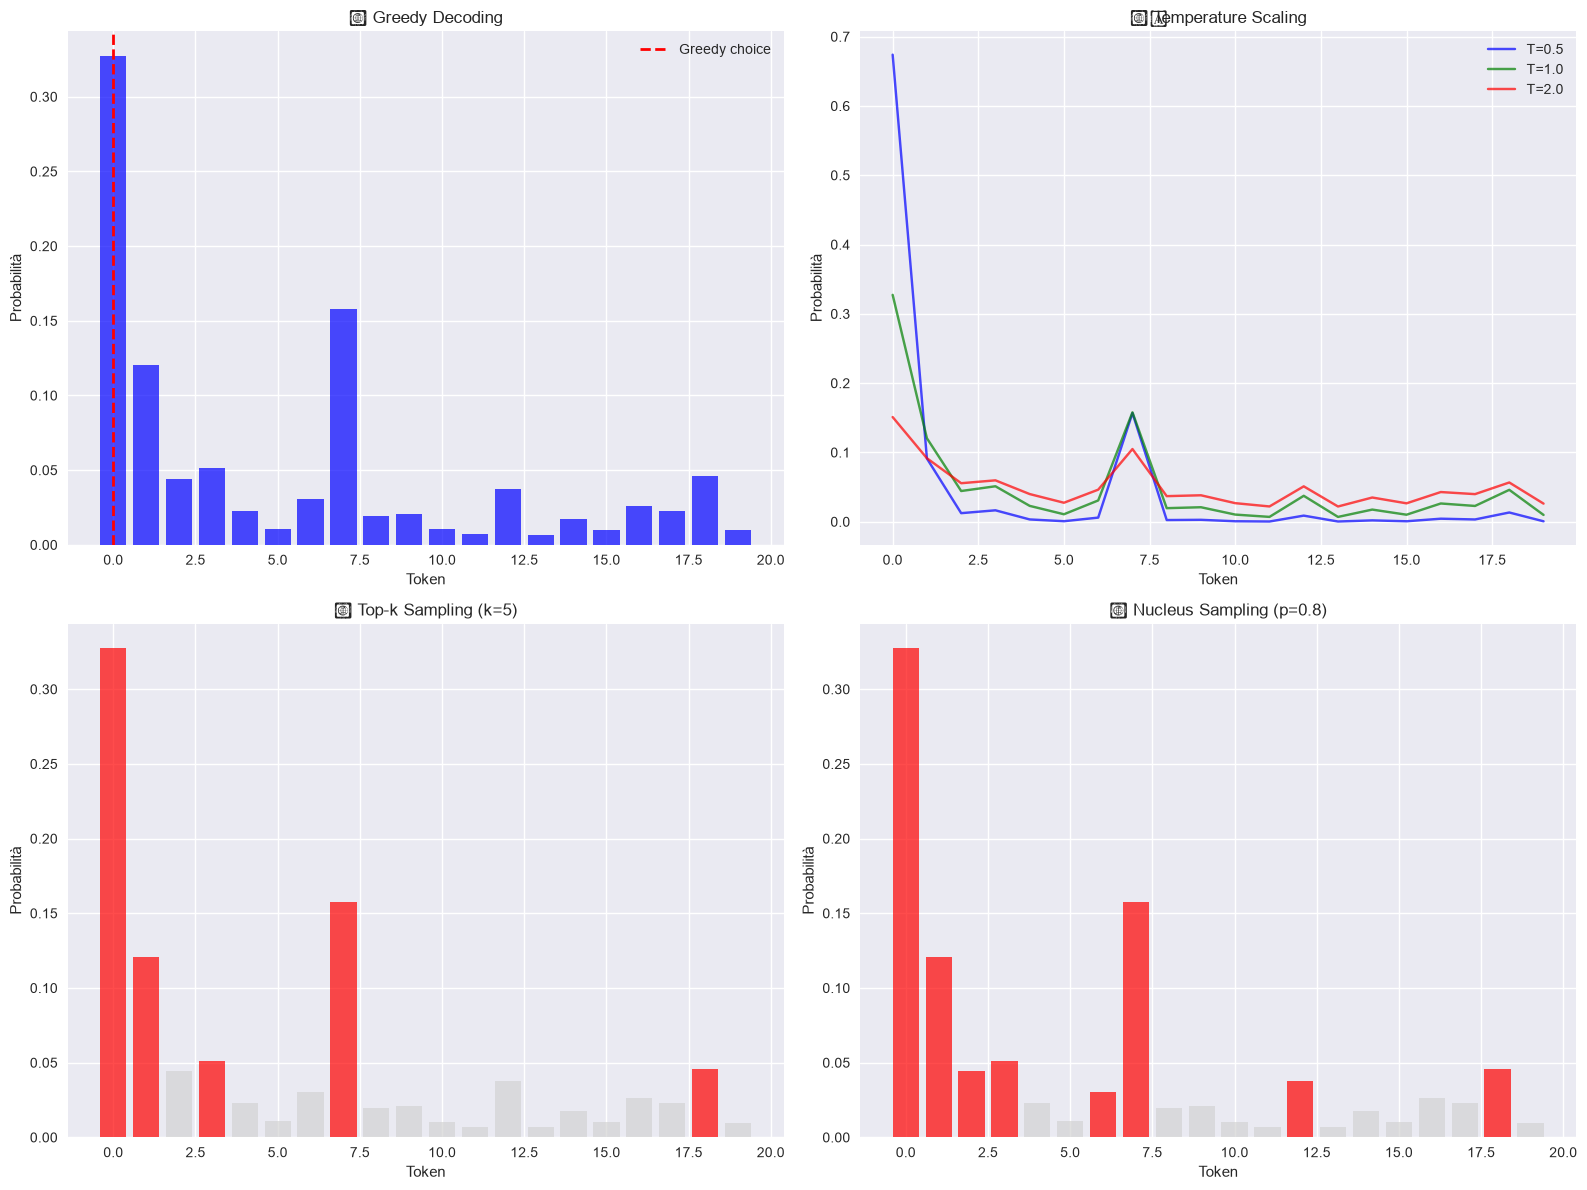


🎛️ CONTROLLO DELLA GENERAZIONE (concetti generali):

🌡️ Temperature:
   • T < 1: Più conservativo, meno creatività
   • T = 1: Distribuzione originale
   • T > 1: Più creativo, meno coerente

🔝 Top-k:
   • k piccolo: Più conservativo
   • k grande: Più diversità

🎪 Top-p (Nucleus):
   • p piccolo: Più conservativo
   • p grande: Più diversità
   • Adattivo: dimensione del nucleus varia


In [13]:
# ============================================================
# BLOCCO 6 — LARGE LANGUAGE MODELS: QUI USIAMO UN MODELLO VERO (GPT-2)
# ============================================================
# LEGAME COL BLOCCO PRECEDENTE: NON riusiamo SimpleTransformer/
# TransformerBlock del Blocco 5. GPT2LMHeadModel/GPT2Tokenizer sono
# classi scritte dentro la libreria Hugging Face "transformers", non
# nel nostro notebook. Concettualmente condividono gli stessi
# ingredienti (attention, feed-forward, residui, layer norm), ma:
#   - la self-attention di GPT-2 è MASCHERATA/CAUSALE (ogni token vede
#     solo i precedenti) -> è un DECODER, non un encoder;
#   - i pesi sono GIA' ADDESTRATI da OpenAI su enormi quantità di testo,
#     scaricati con .from_pretrained('gpt2'), non inizializzati a caso.
#
# OBIETTIVO: mostrare un LLM che genera DAVVERO testo nuovo, e
# introdurre il concetto di diverse strategie di decodifica.
# ============================================================
print("🤖 LARGE LANGUAGE MODELS (LLM)\n")

print("📈 EVOLUZIONE DIMENSIONI LLM:")
llm_evolution = [
    ("2018", "BERT Base", "110M", "Bidirectional encoder"),
    ("2019", "GPT-2", "1.5B", "Autoregressive decoder"),
    ("2020", "GPT-3", "175B", "Few-shot learning"),
    ("2021", "PaLM", "540B", "Scaling laws"),
    ("2022", "ChatGPT", "~175B", "RLHF tuning"),
    ("2023", "GPT-4", "~1.7T", "Multimodal"),
    ("2024", "Claude 3", "~1T+", "Long context")
]

for anno, nome, params, caratteristica in llm_evolution:
    print(f"   {anno}: {nome:<12} {params:<8} - {caratteristica}")

print("\n🧠 CARATTERISTICHE LLM MODERNI:")
caratteristiche = [
    "📊 Miliardi/trilioni di parametri",
    "📚 Training su enormi corpus di testo",
    "🎯 Emergent abilities (capacità emergenti)",
    "🔄 In-context learning (few-shot)",
    "💬 Conversational abilities",
    "🧮 Reasoning e problem solving",
    "🌐 Multilingue e multimodale",
    "⚡ Transfer learning efficace"
]

for caratteristica in caratteristiche:
    print(f"   {caratteristica}")

# ================================================================
# CARICAMENTO DI UN MODELLO VERO E PRE-ADDESTRATO
# ================================================================
print("\n🔬 ESPERIMENTO CON LLM PRE-ADDESTRATO:\n")

try:
    # from_pretrained scarica (o legge dalla cache locale) sia
    # l'architettura sia i PESI GIA' ADDESTRATI di GPT-2 small.
    # Non stiamo costruendo noi il modello: è già pronto.
    print("📥 Caricamento GPT-2 small...")
    tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
    model = GPT2LMHeadModel.from_pretrained('gpt2')

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    print("✅ Modello caricato con successo!")

    num_params = sum(p.numel() for p in model.parameters())
    print(f"\n📊 INFORMAZIONI MODELLO:")
    print(f"   Nome: GPT-2 Small")
    print(f"   Parametri: {num_params:,}")
    print(f"   Vocabolario: {len(tokenizer):,} token")
    print(f"   Contesto massimo: {tokenizer.model_max_length} token")

    # ============================================================
    # GENERAZIONE DI TESTO VERO
    # ============================================================
    # Qui il modello genera DAVVERO nuovo testo, token dopo token,
    # condizionandosi solo sui token già presenti (prompt + token
    # generati finora): questo è il comportamento AUTOREGRESSIVO che
    # rende GPT-2 un decoder.
    print("\n🎨 TEST DI GENERAZIONE:\n")

    prompts = [
        "The future of artificial intelligence is",
        "In a world where robots and humans coexist,",
        "The most important discovery in science was"
    ]

    for i, prompt in enumerate(prompts, 1):
        print(f"🎯 Prompt {i}: '{prompt}'")

        # Trasforma il testo in ID numerici che il modello capisce.
        inputs = tokenizer.encode(prompt, return_tensors='pt')

        # --------------------------------------------------------
        # PARAMETRI CHE CONTROLLANO IL METODO DI GENERAZIONE:
        # do_sample=True + temperature=0.8 => campionamento (sampling)
        # con temperature. E' L'UNICO metodo di decodifica realmente
        # attivato in questa cella: non c'è do_sample=False (greedy),
        # né top_k=..., né top_p=... — quelli li vedremo SOLO come
        # grafici illustrativi più sotto, su dati finti, non su questo
        # modello vero.
        # --------------------------------------------------------
        with torch.no_grad():  # non serve calcolare i gradienti: stiamo solo generando, non allenando
            outputs = model.generate(
                inputs,
                max_length=inputs.shape[1] + 30,
                num_return_sequences=2,
                temperature=0.8,
                do_sample=True,
                pad_token_id=tokenizer.eos_token_id
            )

        for j, output in enumerate(outputs):
            generated_text = tokenizer.decode(output, skip_special_tokens=True)
            print(f"   Generazione {j+1}: {generated_text}")

        print("-" * 80)

except Exception as e:
    print(f"⚠️ Errore nel caricamento del modello: {e}")
    print("💡 Questo può accadere per limitazioni di memoria o connessione")

# ================================================================
# STESSA COSA, CON L'API SEMPLIFICATA "pipeline"
# ================================================================
# E' un'alternativa più comoda a tokenizer+model+generate scritti a
# mano, ma dietro le quinte fa esattamente lo stesso lavoro. Anche qui
# il metodo di generazione è sampling + temperature (do_sample=True).
print("\n🔧 UTILIZZO CON PIPELINE:\n")

try:
    generator = pipeline('text-generation', model='gpt2', tokenizer='gpt2')

    print("📝 GENERAZIONE CON PIPELINE:")

    test_prompts = [
        "Artificial intelligence will",
        "The benefits of machine learning include"
    ]

    for prompt in test_prompts:
        print(f"\n🎯 Prompt: '{prompt}'")

        results = generator(
            prompt,
            max_length=50,
            num_return_sequences=2,
            temperature=0.7,
            do_sample=True
        )

        for i, result in enumerate(results, 1):
            print(f"   {i}. {result['generated_text']}")

except Exception as e:
    print(f"⚠️ Pipeline non disponibile: {e}")

print("\n💡 STRATEGIE DI GENERAZIONE (spiegate qui, ma SOLO 'Sampling + Temperature' è stata usata sopra su GPT-2 vero):")
strategie = [
    "🎯 Greedy Decoding: Sempre il token più probabile",
    "🔍 Beam Search: Mantiene top-k sequenze",
    "🎲 Sampling: Campiona dalla distribuzione",
    "🌡️ Temperature: Controlla la creatività",
    "🔝 Top-k Sampling: Limita ai k token più probabili",
    "🎪 Nucleus (Top-p): Campiona dalla massa di probabilità p"
]

for strategia in strategie:
    print(f"   {strategia}")

# ================================================================
# I 4 GRAFICI SEGUENTI SONO ILLUSTRATIVI: usano una distribuzione di
# probabilità INVENTATA (np.random.randn), NON i punteggi reali che
# GPT-2 ha calcolato sopra per i prompt veri. Servono solo a mostrare
# VISIVAMENTE come cambierebbe la scelta del token con ciascun metodo,
# su un vocabolario finto di 20 "token" di esempio.
# ================================================================
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

vocab_size = 20
logits = np.random.randn(vocab_size)
logits[0] = 3  # imponiamo a mano un token "chiaramente" più probabile
logits[1] = 2
logits[2] = 1

probs = np.exp(logits) / np.sum(np.exp(logits))  # softmax sui logits finti
tokens = [f'token_{i}' for i in range(vocab_size)]

# --- Greedy: si sceglierebbe sempre l'unico token col massimo ---
ax1.bar(range(vocab_size), probs, alpha=0.7, color='blue')
ax1.axvline(x=np.argmax(probs), color='red', linestyle='--', linewidth=2, label='Greedy choice')
ax1.set_title('🎯 Greedy Decoding')
ax1.set_xlabel('Token')
ax1.set_ylabel('Probabilità')
ax1.legend()

# --- Temperature scaling: T basso "appiattisce" le differenze meno, T alto le appiattisce di più ---
temperatures = [0.5, 1.0, 2.0]
colors = ['blue', 'green', 'red']

for temp, color in zip(temperatures, colors):
    temp_probs = np.exp(logits / temp) / np.sum(np.exp(logits / temp))
    ax2.plot(range(vocab_size), temp_probs, alpha=0.7, color=color, label=f'T={temp}')

ax2.set_title('🌡️ Temperature Scaling')
ax2.set_xlabel('Token')
ax2.set_ylabel('Probabilità')
ax2.legend()

# --- Top-k: si considerano solo i k token più probabili, gli altri vengono ignorati ---
k = 5
top_k_indices = np.argsort(probs)[-k:]
colors = ['red' if i in top_k_indices else 'lightgray' for i in range(vocab_size)]

ax3.bar(range(vocab_size), probs, alpha=0.7, color=colors)
ax3.set_title(f'🔝 Top-k Sampling (k={k})')
ax3.set_xlabel('Token')
ax3.set_ylabel('Probabilità')

# --- Top-p (nucleus): si considera il più piccolo insieme di token la cui probabilità cumulata supera p ---
p = 0.8
sorted_indices = np.argsort(probs)[::-1]
cumsum_probs = np.cumsum(probs[sorted_indices])
nucleus_size = np.sum(cumsum_probs <= p) + 1

colors = ['red' if i in sorted_indices[:nucleus_size] else 'lightgray' for i in range(vocab_size)]
ax4.bar(range(vocab_size), probs, alpha=0.7, color=colors)
ax4.set_title(f'🎪 Nucleus Sampling (p={p})')
ax4.set_xlabel('Token')
ax4.set_ylabel('Probabilità')

plt.tight_layout()
plt.show()

print("\n🎛️ CONTROLLO DELLA GENERAZIONE (concetti generali):")
print("\n🌡️ Temperature:")
print("   • T < 1: Più conservativo, meno creatività")
print("   • T = 1: Distribuzione originale")
print("   • T > 1: Più creativo, meno coerente")

print("\n🔝 Top-k:")
print("   • k piccolo: Più conservativo")
print("   • k grande: Più diversità")

print("\n🎪 Top-p (Nucleus):")
print("   • p piccolo: Più conservativo")
print("   • p grande: Più diversità")
print("   • Adattivo: dimensione del nucleus varia")


## 🎯 Blocco 7 — "Applicazioni pratiche": attenzione, è tutto simulato

**🔗 Legame col blocco precedente:** nessun legame a livello di codice. Non richiamiamo né
`GPT2LMHeadModel` né `SimpleTransformer` né le classi numpy dei Blocchi 3-4. `LLMApplications` è una classe
scritta da zero.

**🔍 Cosa viene fatto realmente:** ogni metodo (`text_completion`, `summarization`, `translation`,
`question_answering`, `code_generation`, `creative_writing`) fa un semplice **lookup in un dizionario Python**
pre-scritto, oppure riempie un template, in base a un controllo di parole chiave nel testo in input. **Non
c'è nessuna rete neurale, nessun tokenizer, nessun forward pass, nessuna inferenza.** Guardando solo l'output
stampato può sembrare che "il modello" stia rispondendo in modo intelligente — in realtà sta solo restituendo
testo pre-scritto in base a un confronto di stringhe.

**🎯 Obiettivo:** mostrare a colpo d'occhio i TIPI di compito per cui si usano davvero gli LLM (completamento,
riassunto, traduzione, Q&A, generazione di codice, scrittura creativa) — senza il costo/tempo di eseguire un
modello vero per ciascuno. Non è una dimostrazione di ciò che GPT-2 può fare: è un esempio didattico di *che
tipo* di compiti un LLM (vero) potrebbe affrontare.

In [ ]:
# ============================================================
# BLOCCO 7 — APPLICAZIONI PRATICHE: ⚠️ TUTTO SIMULATO, NESSUN MODELLO
# ============================================================
# LEGAME COL BLOCCO PRECEDENTE: nessuno a livello di codice. Non
# richiamiamo né GPT2LMHeadModel né SimpleTransformer né le classi
# numpy dei Blocchi 3-4. LLMApplications è una classe scritta da zero,
# con dizionari Python già pronti (risposte hard-coded) e semplici
# controlli su parole chiave (if 'keyword' in prompt.lower()).
#
# COSA VIENE FATTO REALMENTE: ogni metodo restituisce una stringa
# scelta da un dizionario in base a corrispondenze testuali, oppure un
# template con lo spazio riempito. NON c'è nessuna rete neurale, nessun
# tokenizer, nessun forward pass, nessuna inferenza. E' un MOCK/DEMO
# che simula come SI COMPORTEREBBE un vero LLM in questi casi d'uso.
#
# OBIETTIVO: mostrare a colpo d'occhio i tipi di task per cui si usano
# davvero gli LLM (completamento, riassunto, traduzione, Q&A,
# generazione di codice, scrittura creativa) — SENZA il costo/tempo di
# eseguire un modello vero per ciascuno.
# ============================================================
print("🚀 APPLICAZIONI PRATICHE DEGLI LLM\n")
print("⚠️  NOTA IMPORTANTE: le funzioni sottostanti sono SIMULATE.")
print("    Non chiamano nessun modello: restituiscono testo pre-scritto")
print("    scelto in base a parole chiave nel prompt.\n")

class LLMApplications:
    """Simulatore di applicazioni LLM.

    Ogni metodo NON esegue un modello: consulta un dizionario di
    risposte pre-scritte (o un template) e ne restituisce una in base
    a un semplice controllo di parole chiave nel testo in input.
    """

    def __init__(self):
        # Dizionario prompt -> completamento: se il prompt in input
        # (case-insensitive) è tra le chiavi, restituiamo il valore
        # associato. Nessuna generazione: solo lookup.
        self.completions = {
            "the weather today is": "sunny with a chance of rain in the afternoon.",
            "artificial intelligence will": "continue to transform industries and improve human productivity.",
            "in the future, technology": "will become more integrated with human daily life.",
            "the best way to learn programming is": "through consistent practice and building real projects."
        }

    def text_completion(self, prompt):
        """Completamento di testo: lookup diretto nel dizionario self.completions.

        Se il prompt (in minuscolo) è una chiave conosciuta, restituisce
        il completamento associato; altrimenti una frase di fallback
        generica. Nessuna rete neurale coinvolta.
        """
        prompt_lower = prompt.lower().strip()

        for key, completion in self.completions.items():
            if key in prompt_lower:
                return f"{prompt} {completion}"

        return f"{prompt} [Completamento generico - modello non disponibile]"

    def summarization(self, text, max_length=50):
        """Riassunto SIMULATO: NON è un vero riassunto semantico.

        Prende semplicemente le prime `max_length` parole del testo
        originale e aggiunge "..." — un troncamento, non una sintesi.
        """
        words = text.split()
        if len(words) <= max_length:
            return text

        summary = " ".join(words[:max_length]) + "..."
        return summary

    def translation(self, text, target_lang="italian"):
        """Traduzione SIMULATA: dizionario di frasi INGLESE->ITALIANO
        già pronte. Se la frase in input è tra le chiavi conosciute
        restituisce la traduzione memorizzata; altrimenti un placeholder.
        Non c'è nessun modello di traduzione reale.
        """
        translations = {
            "hello, how are you?": "Ciao, come stai?",
            "the weather is beautiful today": "Il tempo è bellissimo oggi",
            "artificial intelligence is fascinating": "L'intelligenza artificiale è affascinante",
            "thank you for your help": "Grazie per il tuo aiuto"
        }

        text_lower = text.lower().strip()
        if text_lower in translations:
            return translations[text_lower]

        return f"[Traduzione simulata di: '{text}']"

    def question_answering(self, question, context=None):
        """Q&A SIMULATO: dizionario domanda -> risposta pre-scritta.

        Confronta la domanda (in minuscolo) con un set fisso di
        domande conosciute. Nessuna comprensione reale del linguaggio,
        nessun retrieval, nessun modello.
        """
        qa_pairs = {
            "what is artificial intelligence?": "AI is the simulation of human intelligence in machines that are programmed to think and learn.",
            "how do neural networks work?": "Neural networks work by processing information through interconnected nodes that adjust their connections based on training data.",
            "what is machine learning?": "Machine learning is a subset of AI that enables computers to learn and improve from experience without being explicitly programmed.",
            "what is deep learning?": "Deep learning uses multi-layered neural networks to model and understand complex patterns in data."
        }

        question_lower = question.lower().strip()

        for key, answer in qa_pairs.items():
            if key in question_lower or question_lower in key:
                return answer

        return "Mi dispiace, non ho informazioni specifiche su questa domanda. [Risposta simulata]"

    def code_generation(self, description):
        """Generazione di codice SIMULATA: dizionario descrizione -> snippet
        di codice già scritto a mano (non generato da un modello).
        Il controllo è per parola chiave contenuta nella descrizione.
        """
        code_templates = {
            "fibonacci": '''def fibonacci(n):
    if n <= 1:
        return n
    return fibonacci(n-1) + fibonacci(n-2)''',
            "sort list": '''def sort_list(lst):
    return sorted(lst)''',
            "reverse string": '''def reverse_string(s):
    return s[::-1]''',
            "factorial": '''def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n-1)'''
        }

        description_lower = description.lower()

        for key, code in code_templates.items():
            if key in description_lower:
                return code

        return "# Codice non disponibile per questa richiesta [Simulazione]"

    def creative_writing(self, prompt, style="story"):
        """Scrittura creativa SIMULATA: template di storie già scritti,
        con lo spazio per il prompt riempito tramite un f-string.
        Nessuna generazione creativa reale: è un "riempi gli spazi".
        """
        templates = {
            "story": f"Once upon a time, {prompt.lower()}. This led to an incredible adventure that changed everything forever.",
            "poem": f"In realms where {prompt.lower()} does dwell,\nA tale of wonder I shall tell,\nWith words that dance and thoughts that soar,\nCreating magic, and so much more.",
            "dialogue": f'"{prompt}?" she asked with curiosity.\n"Indeed," he replied, "it\'s more complex than it seems."'
        }

        return templates.get(style, templates["story"])

# ================================================================
# ISTANZA E DEMO: chiamiamo davvero questi metodi Python, ma
# ricordiamo che dietro non c'è nessun modello — solo i dizionari sopra
# ================================================================
llm_apps = LLMApplications()

print("=" * 70)
print("1️⃣  TEXT COMPLETION (lookup in dizionario)")
print("=" * 70)

completion_prompts = [
    "The weather today is",
    "Artificial intelligence will",
    "In the future, technology"
]

for prompt in completion_prompts:
    result = llm_apps.text_completion(prompt)
    print(f"📝 Prompt: '{prompt}'")
    print(f"✅ Completamento: '{result}'\n")

print("=" * 70)
print("2️⃣  SUMMARIZATION (troncamento alle prime N parole, non sintesi)")
print("=" * 70)

long_text = """
Artificial intelligence has revolutionized numerous industries over the past decade.
From healthcare to finance, AI systems are now capable of performing complex tasks
that were once thought to be exclusively human domains. Machine learning algorithms
can now diagnose diseases, predict market trends, and even create art. However,
this rapid advancement also raises important questions about ethics, employment,
and the future relationship between humans and artificial intelligence systems.
"""

summary = llm_apps.summarization(long_text.strip(), max_length=20)
print(f"📄 Testo originale ({len(long_text.split())} parole):")
print(long_text.strip())
print(f"\n📝 'Riassunto' ({len(summary.split())} parole, in realtà solo troncato):")
print(summary)

print("\n" + "=" * 70)
print("3️⃣  TRANSLATION (dizionario frasi note EN->IT)")
print("=" * 70)

translation_texts = [
    "Hello, how are you?",
    "The weather is beautiful today",
    "Artificial intelligence is fascinating"
]

for text in translation_texts:
    translation = llm_apps.translation(text)
    print(f"🇬🇧 EN: '{text}'")
    print(f"🇮🇹 IT: '{translation}'\n")

print("=" * 70)
print("4️⃣  QUESTION ANSWERING (dizionario domanda->risposta)")
print("=" * 70)

questions = [
    "What is artificial intelligence?",
    "How do neural networks work?",
    "What is machine learning?"
]

for question in questions:
    answer = llm_apps.question_answering(question)
    print(f"❓ Domanda: '{question}'")
    print(f"💡 Risposta: '{answer}'\n")

print("=" * 70)
print("5️⃣  CODE GENERATION (snippet pre-scritti, keyword matching)")
print("=" * 70)

code_requests = [
    "Write a function to calculate fibonacci numbers",
    "Create a function to sort a list",
    "Write code to reverse a string"
]

for request in code_requests:
    code = llm_apps.code_generation(request)
    print(f"💻 Richiesta: '{request}'")
    print(f"📜 Codice generato:\n{code}\n")

print("=" * 70)
print("6️⃣  CREATIVE WRITING (template con spazi riempiti)")
print("=" * 70)

creative_prompt = "a robot discovers emotions"

story = llm_apps.creative_writing(creative_prompt, "story")
print(f"📖 Storia (prompt: '{creative_prompt}'):")
print(story)

poem = llm_apps.creative_writing(creative_prompt, "poem")
print(f"\n🎭 Poesia (stesso prompt):")
print(poem)

print("\n" + "=" * 70)
print("💡 RIEPILOGO: perché questo blocco è utile anche se simulato")
print("=" * 70)
print("""
Questo blocco NON dimostra le capacità di un vero LLM: dimostra invece
QUALI TIPI DI COMPITO si affidano tipicamente a un LLM nel mondo reale.
Per vedere le stesse categorie di compito eseguite da un modello VERO,
servirebbe collegare ciascuna di queste funzioni a GPT-2 (Blocco 6) o
a un modello più grande — cosa che questo notebook non fa.
""")


**Riassumendo il Blocco 7:** nessuna riga di questo blocco chiama `model.generate`,
`pipeline`, o qualunque altra funzione dei Blocchi 5-6. È simulazione pura tramite dizionari.

## 🎓 Blocco 8 — Riepilogo finale

**🔗 Legame col blocco precedente:** non introduce nulla di nuovo dal punto di vista del codice o dei modelli.
Riprende, solo a parole/tabelle/grafici, i concetti già incontrati nei Blocchi 2-7.

**🔍 Cosa viene fatto realmente:** vengono costruite solo tabelle di confronto e figure `matplotlib`
riassuntive. Nessun modello viene creato, addestrato o eseguito in questo blocco.

**🎯 Obiettivo:** fissare una mappa d'insieme di tutto il percorso, e rispondere esplicitamente alla domanda
guida posta all'inizio della lezione.

In [ ]:
# ============================================================
# BLOCCO 8 — RIEPILOGO FINALE (solo grafici/tabelle riassuntivi)
# ============================================================
# LEGAME COL BLOCCO PRECEDENTE: non introduce nulla di nuovo dal punto
# di vista del codice/modelli. Riprende SOLO a parole (stringhe,
# tabelle, grafici) i concetti già incontrati nei Blocchi 2-7, per
# fissarli in una vista d'insieme.
#
# OBIETTIVO: dare una mappa finale di confronto tra le architetture
# viste (RNN teorica, Self-Attention/Multi-Head/Transformer "a mano" o
# non addestrati, GPT-2 vero) e riepilogare la timeline storica.
#
# COSA VIENE FATTO REALMENTE: costruiamo solo figure matplotlib e
# stampe di riepilogo. Nessun modello viene creato, addestrato o
# eseguito in questa cella.
# ============================================================
print("📋 RIEPILOGO FINALE: DA RNN A LLM\n")

print("🔄 EVOLUZIONE DELLE ARCHITETTURE:")
print("=" * 60)

evoluzione = [
    ("RNN/LSTM", "Elaborazione sequenziale", "Memoria limitata, lento"),
    ("Self-Attention", "Attenzione diretta tra token", "Base del Transformer (Blocco 3)"),
    ("Multi-Head Attention", "Attenzioni parallele specializzate", "Cattura più tipi di relazioni (Blocco 4)"),
    ("Transformer Encoder", "Stack completo, bidirezionale", "Costruito ma non addestrato (Blocco 5)"),
    ("GPT-2 (Decoder)", "Autoregressivo, causale, pre-addestrato", "Generazione reale di testo (Blocco 6)"),
    ("LLM moderni", "Miliardi/trilioni di parametri", "Capacità emergenti, in-context learning")
]

for nome, caratteristica, nota in evoluzione:
    print(f"   📌 {nome}")
    print(f"      Caratteristica: {caratteristica}")
    print(f"      Nota: {nota}\n")

# ================================================================
# TABELLA COMPARATIVA: cosa abbiamo VISTO in ciascun blocco vs cosa
# succederebbe in un vero LLM di produzione
# ================================================================
print("=" * 60)
print("📊 COSA ERA 'VERO' E COSA ERA SOLO ILLUSTRATIVO IN QUESTO NOTEBOOK")
print("=" * 60)

confronto = pd.DataFrame({
    "Blocco": [
        "3 - Self-Attention",
        "4 - Multi-Head Attention",
        "5 - Transformer (Keras)",
        "6 - GPT-2",
        "7 - Applicazioni"
    ],
    "Pesi": [
        "Identità (fissi)",
        "Random (fissi)",
        "Random Keras (mai allenati)",
        "Pre-addestrati (veri)",
        "Nessun peso: dizionari"
    ],
    "Training eseguito?": ["No", "No", "No", "No (già fatto da OpenAI)", "N/A"],
    "Encoder o Decoder?": [
        "Nessuna maschera (bidirezionale)",
        "Nessuna maschera (bidirezionale)",
        "Encoder (bidirezionale)",
        "Decoder (causale/autoregressivo)",
        "N/A"
    ],
    "Output linguisticamente valido?": ["No", "No", "No", "Sì", "Sì (ma pre-scritto)"]
})
print(confronto.to_string(index=False))

# ================================================================
# VISUALIZZAZIONE: timeline + confronto dimensioni + capacità + badge finale
# ================================================================
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# --- Timeline storica (solo disegno, stessi dati del Blocco 2) ---
years = [2017, 2018, 2019, 2020, 2022, 2023]
events = ['Transformer', 'BERT', 'GPT-2', 'GPT-3', 'ChatGPT', 'GPT-4']
importance = [10, 7, 8, 9, 10, 9]

ax1.scatter(years, importance, s=[i*50 for i in importance], alpha=0.7, c='blue')
for i, event in enumerate(events):
    ax1.annotate(event, (years[i], importance[i]), xytext=(5, 5),
                textcoords='offset points', fontsize=9)
ax1.set_title('📅 Timeline Evoluzione Transformer/LLM')
ax1.set_xlabel('Anno')
ax1.set_ylabel('Impatto Relativo')
ax1.grid(True, alpha=0.3)

# --- Crescita dimensioni modelli (scala log, dati illustrativi) ---
models = ['BERT', 'GPT-2', 'GPT-3', 'PaLM', 'GPT-4']
params = [0.11, 1.5, 175, 540, 1700]

ax2.bar(models, params, color=['blue', 'green', 'orange', 'red', 'purple'], alpha=0.7)
ax2.set_yscale('log')
ax2.set_title('📈 Crescita Parametri Modelli (Miliardi)')
ax2.set_ylabel('Parametri (Log Scale)')
ax2.tick_params(axis='x', rotation=45)

# --- Confronto capacità (RNN vs Transformer, valutazione qualitativa) ---
categories = ['Parallelizzazione', 'Memoria Lungo\nRaggio', 'Velocità\nTraining', 'Scalabilità', 'Interpretabilità']
rnn_scores = [2, 3, 3, 4, 6]
transformer_scores = [9, 8, 7, 9, 5]

x = np.arange(len(categories))
width = 0.35

ax3.bar(x - width/2, rnn_scores, width, label='RNN', alpha=0.7, color='lightcoral')
ax3.bar(x + width/2, transformer_scores, width, label='Transformer', alpha=0.7, color='lightblue')
ax3.set_title('⚖️ RNN vs Transformer (valutazione qualitativa)')
ax3.set_xticks(x)
ax3.set_xticklabels(categories, fontsize=8)
ax3.legend()
ax3.set_ylabel('Score (1-10)')

# --- Badge finale riassuntivo (solo testo/decorazione) ---
ax4.text(0.5, 0.8, '🎓 PERCORSO COMPLETATO', ha='center', va='center',
         fontsize=16, fontweight='bold', transform=ax4.transAxes)
ax4.text(0.5, 0.6, 'RNN → Self-Attention → Multi-Head\n→ Transformer → GPT-2 → Applicazioni',
         ha='center', va='center', fontsize=11, transform=ax4.transAxes)
ax4.text(0.5, 0.3, '✅ Concetti teorici\n✅ Implementazione manuale\n✅ Modello pre-addestrato reale\n✅ Casi d\'uso',
         ha='center', va='center', fontsize=10, transform=ax4.transAxes)
ax4.axis('off')

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("🎯 DOMANDE PER LA DISCUSSIONE IN CLASSE")
print("=" * 60)
domande = [
    "1) Perché la self-attention del Blocco 3 non richiede training per essere 'eseguita', ma non produce output linguisticamente sensati?",
    "2) Cosa distingue, nel codice, un blocco 'encoder' (Blocco 5) da un blocco 'decoder' (Blocco 6)?",
    "3) Se dovessimo rendere il Transformer del Blocco 5 realmente funzionante, quali passi mancano (rispetto a GPT-2)?",
    "4) Perché il Blocco 7 non è un vero LLM, anche se il suo output sembra plausibile?"
]
for domanda in domande:
    print(f"   {domanda}")

print("\n👋 Fine del notebook annotato.")


## 🎓 La risposta alla domanda guida

> **Il modello costruito in questo notebook è "solo encoder"?**

**Risposta:** il notebook non contiene un'unica architettura, ma **due architetture diverse e indipendenti**:

1. Il Transformer costruito "a mano" con Keras (Blocco 5) **è encoder-only** (nessuna maschera causale),
   **non addestrato**, usato solo per un test di shape con dati casuali. Non genera mai testo.
2. Il modello che genera davvero testo nel notebook è **GPT-2** (Blocco 6), che è **decoder-only** e
   **pre-addestrato**, caricato da Hugging Face — e anche lì, l'unico metodo di generazione realmente
   eseguito è sampling + temperature.
3. I due non sono collegati tra loro nel codice: sono due esempi paralleli, uno "didattico/giocattolo"
   (encoder, Blocchi 3-5) e uno "reale" (decoder, Blocco 6).
4. Il Blocco 7 ("applicazioni pratiche") non usa nessun modello: è tutto scritto a mano con dizionari, a scopo
   puramente illustrativo.

### 💬 Domande per la discussione in aula

1. Perché una self-attention *senza* maschera causale non può, da sola, essere usata per generare testo parola
   per parola in modo autoregressivo?
2. Cosa cambierebbe nel codice del Blocco 5 (`TransformerBlock`) se volessimo trasformarlo in un vero blocco
   decoder autoregressivo?
3. Perché il Blocco 5, pur avendo un `Dense(vocab_size)` in uscita, non produce output linguisticamente
   sensati anche se lo eseguissimo su del testo vero?
4. Che differenza c'è fra un modello **encoder-only** (BERT), **decoder-only** (GPT) e **encoder-decoder**
   (T5, il Transformer originale per la traduzione)? Nessuno dei tre è stato costruito per intero in questo
   notebook — quale mancava del tutto?
5. Nel Blocco 6, perché solo "sampling + temperature" è considerato realmente usato, mentre greedy/top-k/
   nucleus sono solo illustrati?